In [1]:
# ── JUPYTERLAB KURULUM
# İlk çalıştırmada aşağıdaki satırı etkinleştirip çalıştırın, sonra tekrar yorum satırına alın.
# %pip install optuna lightgbm shap openpyxl -q

import subprocess, sys

REQUIRED = ["optuna", "lightgbm", "shap", "openpyxl"]
missing = []
for pkg in REQUIRED:
    try:
        __import__(pkg)
    except ImportError:
        missing.append(pkg)

if missing:
    print(f"Eksik paketler kuruluyor: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)
    print("Kurulum tamamlandı. Kernel'i yeniden başlatın (Kernel → Restart Kernel).")
else:
    print("Tüm bağımlılıklar mevcut.")


C:\Users\Hakan\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Tüm bağımlılıklar mevcut.


In [2]:
# ── DOSYA YOLU AYARI
# DATA_PATH: Excel dosyanızın konumunu aşağıya girin.
# Notebook ile aynı klasördeyse sadece dosya adını yazın.
# Farklı klasördeyse tam yolu girin, örneğin: r"C:/Users/Hakan/Datasets/ankara_istanbul.xlsx"

import os
from pathlib import Path

DATA_PATH   = "ankara_istanbul_full.xlsx"      # ← kendi dosya yolunuza göre güncelleyin
RESULTS_DIR = Path("results_q1")          # ← çıktıların kaydedileceği klasör

RESULTS_DIR.mkdir(exist_ok=True)

if not Path(DATA_PATH).exists():
    print(f"UYARI: Veri dosyası bulunamadı → {Path(DATA_PATH).resolve()}")
    print("DATA_PATH değişkenini güncelleyip hücreyi yeniden çalıştırın.")
else:
    print(f"Veri dosyası bulundu : {Path(DATA_PATH).resolve()}")
    print(f"Sonuçlar klasörü    : {RESULTS_DIR.resolve()}")


Veri dosyası bulundu : C:\Users\Hakan\AppData\Local\Programs\Python\Python313\Scripts\ankara_istanbul_full.xlsx
Sonuçlar klasörü    : C:\Users\Hakan\AppData\Local\Programs\Python\Python313\Scripts\results_q1


# Housing Price Prediction: Cross-City Bayesian Pipeline Optimization with Spatial XAI
### Q1 Research Framework — Istanbul & Ankara

**Research Questions:**
1. Can a Bayesian-optimized AutoML pipeline outperform individual ML baselines in heterogeneous emerging real estate markets?
2. Do optimal pipeline configurations transfer across cities, and which hyperparameters are market-invariant vs. city-specific?
3. What spatial and structural factors drive housing prices differently across Istanbul and Ankara?

**Novel Contributions:**
1. Cross-city warm-start Optuna optimization (meta-learning prior transfer)
2. Spatial SHAP analysis revealing city-level feature importance heterogeneity
3. Ablation study isolating each pipeline component's contribution
4. Rigorous statistical validation (Wilcoxon + Friedman tests across 30 seeds)

---
## 0. Environment Setup

In [3]:
# -- Core
import warnings, os, json, time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

# -- ML
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor,
    HistGradientBoostingRegressor, VotingRegressor,
    GradientBoostingRegressor, StackingRegressor
)
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder

# -- LightGBM
try:
    import lightgbm as lgb
    LGB_AVAILABLE = True
    print('LightGBM version:', lgb.__version__)
except ImportError:
    LGB_AVAILABLE = False
    print('LightGBM bulunamadi -- sadece sklearn modelleri kullanilacak.')

# -- Optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# -- Visualization
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False
})

# -- Config
RANDOM_SEED         = 42
N_OPTUNA_TRIALS     = 300
OPTUNA_PATIENCE     = 30
OPTUNA_SAMPLE_SIZE  = None   # None = tam veri kullan
N_BOOTSTRAP         = 30
N_OUTER_FOLDS       = 5
N_INNER_FOLDS       = 5
RESULTS_DIR.mkdir(exist_ok=True)

np.random.seed(RANDOM_SEED)
print('Setup OK -- NumPy:', np.__version__, '| Pandas:', pd.__version__, '| Optuna:', optuna.__version__)


LightGBM version: 4.6.0
Setup OK -- NumPy: 2.3.2 | Pandas: 2.3.2 | Optuna: 4.8.0


---
## 1. Faz 1 — Veri Yükleme, Temizleme & EDA

In [4]:
# ── 1.1 Veri Yükleme
raw = pd.read_excel(DATA_PATH)

# Encoding & boşluk düzeltme
raw['province'] = raw['province'].str.strip().str.replace('\xa0', '', regex=False)
raw['district'] = raw['district'].str.strip()
raw['street']   = raw['street'].str.strip()

# Province standardizasyonu
raw['city'] = raw['province'].apply(
    lambda x: 'Istanbul' if 'stanbul' in x else ('Ankara' if 'Ankara' in x else x)
)

print('Ham veri:')
print(raw.shape)
print(raw['city'].value_counts())
print(raw.head(3))

Ham veri:
(72690, 9)
city
Istanbul    36514
Ankara      36176
Name: count, dtype: int64
       Price  province district                     street  Room   m2  floor  \
0  999000000  İstanbul   Beykoz             Paşabahçe Mah.     6  350      0   
1  875000000  İstanbul  Sarıyer               Yeniköy Mah.     7  400      0   
2  860000000  İstanbul  Beyoğlu  Katip Mustafa Çelebi Mah.    28  260     -1   

   age      city  
0   10  Istanbul  
1   10  Istanbul  
2   10  Istanbul  


In [5]:
# -- 1.2 Room Kolonu Normalize
# Oda sayisi direkt integer olarak kaydedilmis

raw['room_count'] = raw['Room'].clip(0, 20)
raw['living_room'] = 1  # varsayilan: 1 salon
raw['total_rooms'] = raw['room_count'] + raw['living_room']

print('Room dagilimi:')
print(raw['room_count'].value_counts().sort_index().head(15))


Room dagilimi:
room_count
1       241
2      5751
3     21205
4     29689
5      8828
6      3561
7      1721
8       804
9       291
10      183
11       77
12       97
13       37
14       36
15       29
Name: count, dtype: int64


=== Raw Statistics (by City) ===
           count        mean         std      min        25%        50%  \
city                                                                      
Ankara    36,176   6,877,436  10,862,989  235,000  3,550,000  4,790,000   
Istanbul  36,514  16,113,845  35,055,406  250,000  4,850,000  7,750,000   

                 75%          max  
city                               
Ankara     7,023,875  579,000,000  
Istanbul  16,000,000  999,000,000  


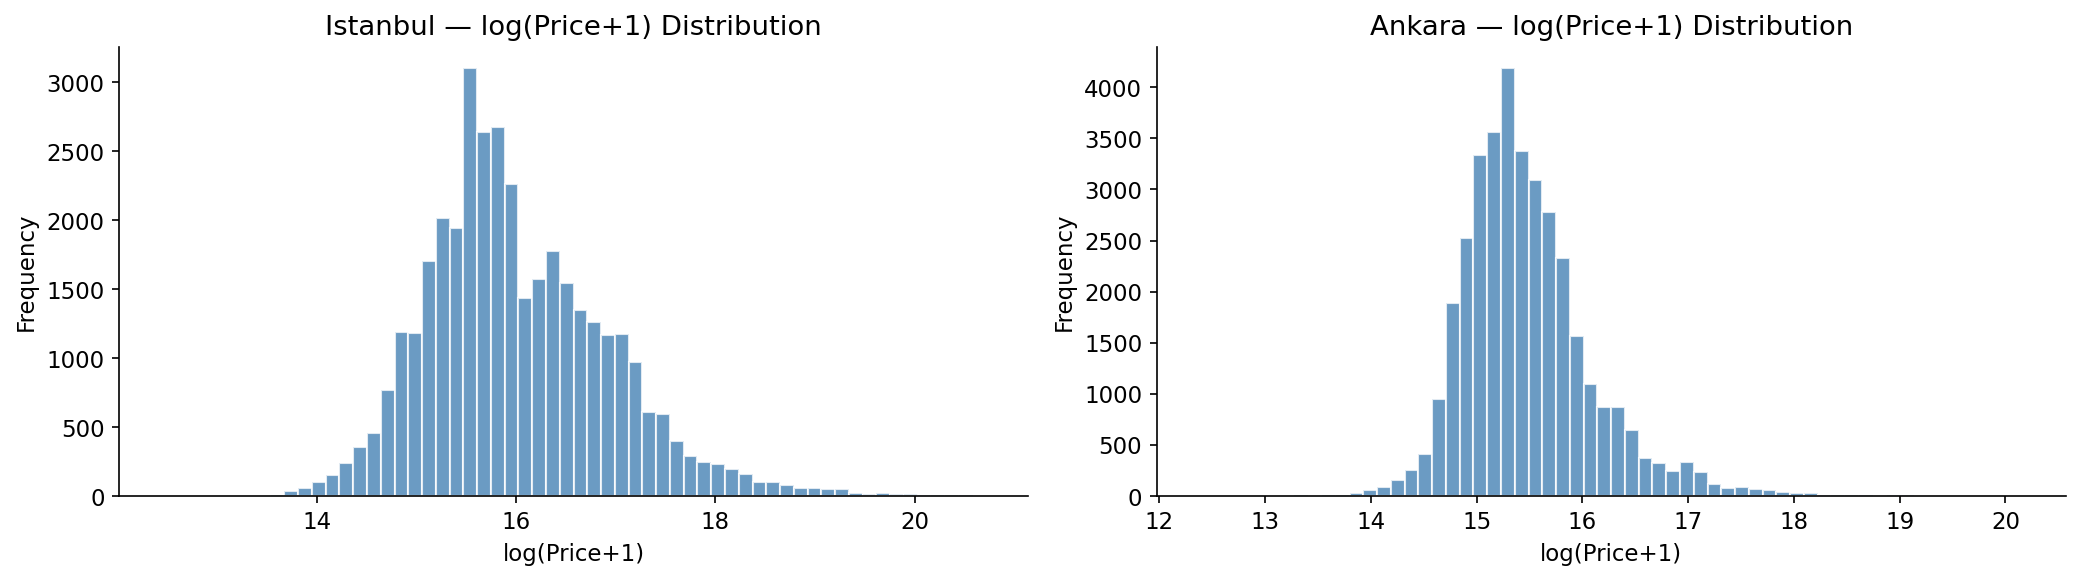

In [6]:
# ── 1.3 Aykırı Değer Tespiti (Temizleme öncesi istatistikler)
print('=== Raw Statistics (by City) ===')
print(raw.groupby('city')['Price'].describe().applymap(lambda x: f'{x:,.0f}'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, city in zip(axes, ['Istanbul', 'Ankara']):
    sub = raw[raw['city'] == city]['Price']
    ax.hist(np.log1p(sub), bins=60, color='steelblue', edgecolor='white', alpha=0.8)
    ax.set_title(f'{city} — log(Price+1) Distribution')
    ax.set_xlabel('log(Price+1)')
    ax.set_ylabel('Frequency')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig1_price_distribution_raw.png', bbox_inches='tight')
plt.show()

In [7]:
# ── 1.4 Temizleme Pipeline

def clean_data(df: pd.DataFrame, 
               price_lo_pct: float = 0.01, 
               price_hi_pct: float = 0.99,
               m2_max: int = 500,
               room_max: int = 10) -> pd.DataFrame:
    """
    Tekrarlanabilir veri temizleme. 
    Her şehir için ayrı ayrı percentile hesaplar (data leakage önleme).
    """
    clean_dfs = []
    for city, sub in df.groupby('city'):
        lo = sub['Price'].quantile(price_lo_pct)
        hi = sub['Price'].quantile(price_hi_pct)
        sub = sub[(sub['Price'] >= lo) & (sub['Price'] <= hi)]
        sub = sub[sub['m2'] <= m2_max]
        sub = sub[sub['m2'] >= 20]
        sub = sub[sub['room_count'] <= room_max]
        sub = sub[sub['room_count'] >= 0]
        clean_dfs.append(sub)
    
    result = pd.concat(clean_dfs, ignore_index=True)
    return result

df = clean_data(raw)

print(f'Ham: {raw.shape[0]:,} → Temiz: {df.shape[0]:,} (kaldırılan: {raw.shape[0]-df.shape[0]:,})')
print(df.groupby('city').size())

Ham: 72,690 → Temiz: 70,568 (kaldırılan: 2,122)
city
Ankara      35255
Istanbul    35313
dtype: int64


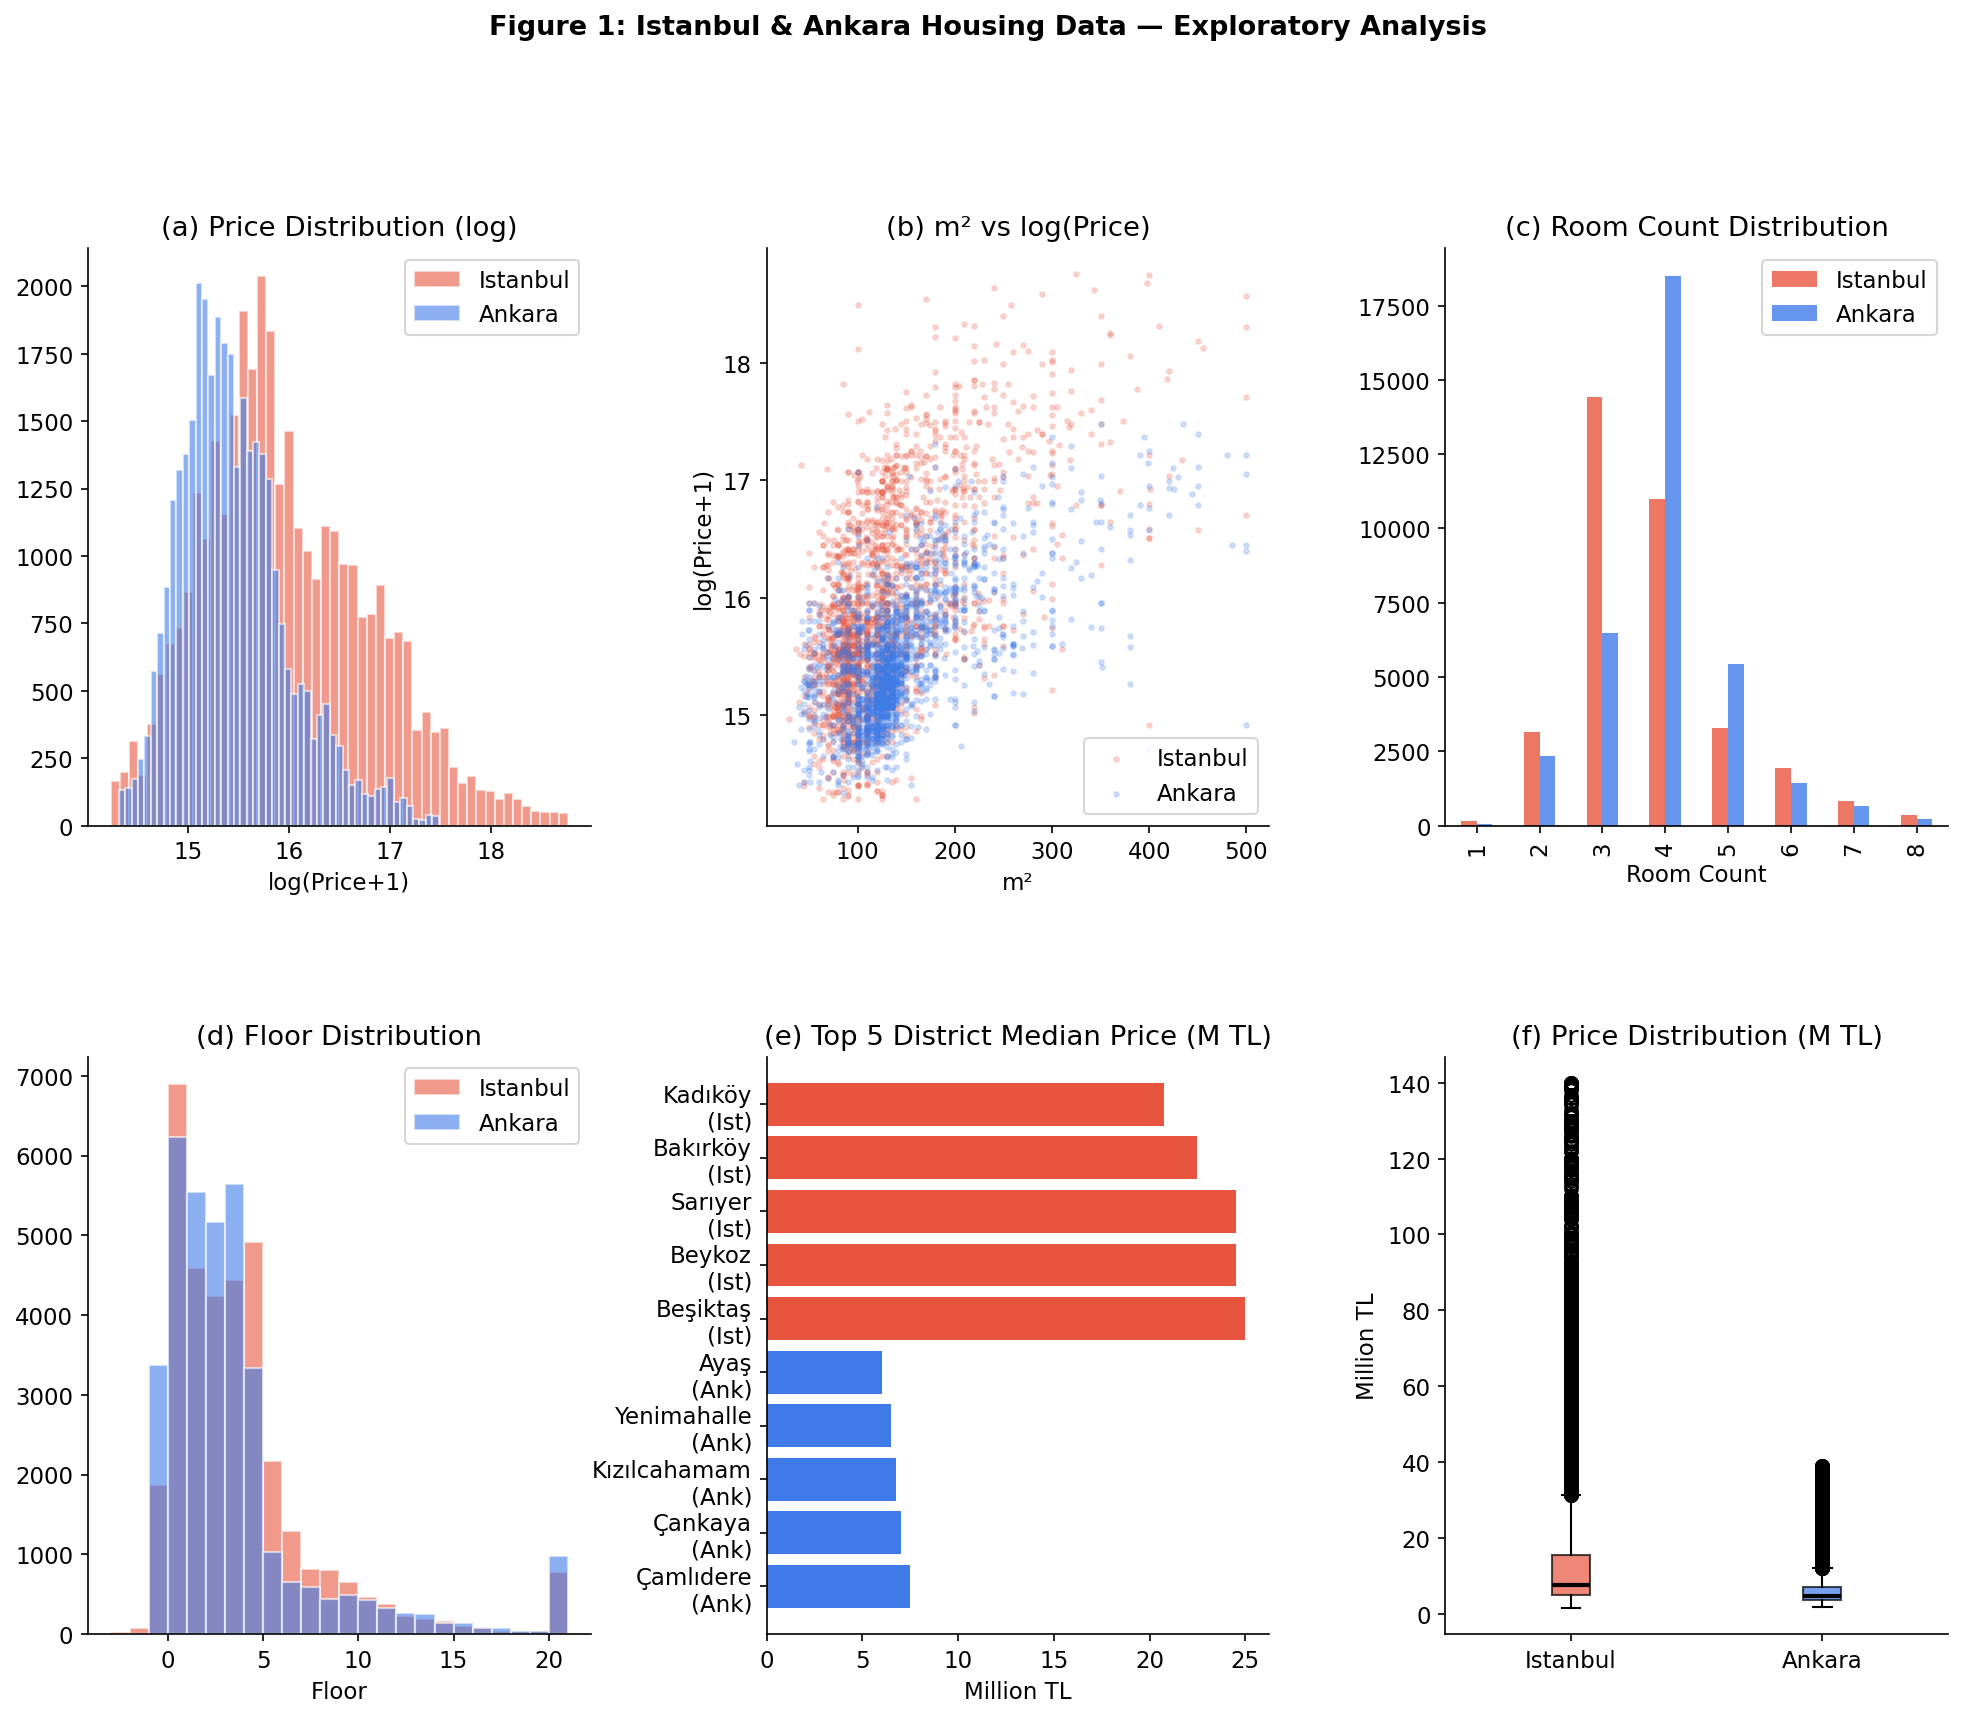

In [8]:
# ── 1.5 EDA — Makaleye Gidecek Görseller

fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

colors = {'Istanbul': '#E8553E', 'Ankara': '#3E7BE8'}

# 1. Price distribution (cleaned)
ax1 = fig.add_subplot(gs[0, 0])
for city, color in colors.items():
    sub = df[df['city'] == city]['Price']
    ax1.hist(np.log1p(sub), bins=50, alpha=0.6, color=color, label=city, edgecolor='white')
ax1.set_title('(a) Price Distribution (log)')
ax1.set_xlabel('log(Price+1)')
ax1.legend()

# 2. m2 vs Price (scatter)
ax2 = fig.add_subplot(gs[0, 1])
for city, color in colors.items():
    sub = df[df['city'] == city].sample(min(2000, len(df[df['city']==city])), random_state=42)
    ax2.scatter(sub['m2'], np.log1p(sub['Price']), alpha=0.2, color=color, s=5, label=city)
ax2.set_title('(b) m² vs log(Price)')
ax2.set_xlabel('m²')
ax2.set_ylabel('log(Price+1)')
ax2.legend()

# 3. Oda sayısı dağılımı
ax3 = fig.add_subplot(gs[0, 2])
room_counts = df.groupby(['city', 'room_count']).size().unstack(fill_value=0)
room_counts.loc[['Istanbul', 'Ankara'], room_counts.columns[:8]].T.plot(kind='bar', ax=ax3, color=list(colors.values()), alpha=0.8)
ax3.set_title('(c) Room Count Distribution')
ax3.set_xlabel('Room Count')
ax3.legend()

# 4. Kat dağılımı
ax4 = fig.add_subplot(gs[1, 0])
for city, color in colors.items():
    sub = df[df['city'] == city]['floor']
    ax4.hist(sub, bins=range(-3, 22), alpha=0.6, color=color, label=city, edgecolor='white')
ax4.set_title('(d) Floor Distribution')
ax4.set_xlabel('Floor')
ax4.legend()

# 5. İlçe bazında medyan fiyat (top 10)
ax5 = fig.add_subplot(gs[1, 1])
city_medians = df.groupby(['city', 'district'])['Price'].median().reset_index()
top_districts = city_medians.groupby('city').apply(
    lambda x: x.nlargest(5, 'Price')
).reset_index(drop=True)
top_districts['label'] = top_districts['district'] + '\n(' + top_districts['city'].str[:3] + ')'
bars = ax5.barh(top_districts['label'], top_districts['Price']/1e6, 
                color=[colors[c] for c in top_districts['city']])
ax5.set_title('(e) Top 5 District Median Price (M TL)')
ax5.set_xlabel('Million TL')

# 6. Price boxplot
ax6 = fig.add_subplot(gs[1, 2])
data_box = [df[df['city']=='Istanbul']['Price'].values/1e6,
            df[df['city']=='Ankara']['Price'].values/1e6]
bp = ax6.boxplot(data_box, labels=['Istanbul', 'Ankara'], patch_artist=True,
                 medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], colors.values()):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax6.set_title('(f) Price Distribution (M TL)')
ax6.set_ylabel('Million TL')

plt.suptitle('Figure 1: Istanbul & Ankara Housing Data — Exploratory Analysis', 
             fontsize=13, fontweight='bold', y=1.01)
plt.savefig(RESULTS_DIR / 'fig1_eda.png', bbox_inches='tight')
plt.show()

In [9]:
# ── 1.6 Betimsel İstatistik Tablosu (Makale Tablo 1)
from scipy import stats

def descriptive_stats(df):
    rows = []
    for city in ['Istanbul', 'Ankara']:
        sub = df[df['city'] == city]
        rows.append({
            'City': city,
            'N': len(sub),
            'Districts': sub['district'].nunique(),
            'Price Mean (M TL)': f"{sub['Price'].mean()/1e6:.2f}",
            'Price Median (M TL)': f"{sub['Price'].median()/1e6:.2f}",
            'Price Std (M TL)': f"{sub['Price'].std()/1e6:.2f}",
            'm2 Mean': f"{sub['m2'].mean():.1f}",
            'm2 Median': f"{sub['m2'].median():.1f}",
            'Room Mean': f"{sub['room_count'].mean():.2f}",
            'Floor Mean': f"{sub['floor'].mean():.2f}",
        })
    return pd.DataFrame(rows).set_index('City')

tablo1 = descriptive_stats(df)
print('=== TABLE 1: Descriptive Statistics ===')
display(tablo1.T)
tablo1.T.to_csv(RESULTS_DIR / 'table1_descriptive.csv')

# Mann-Whitney U testi (iki şehir fiyat dağılımı istatistiksel olarak farklı mı?)
u_stat, p_val = stats.mannwhitneyu(
    df[df['city']=='Istanbul']['Price'],
    df[df['city']=='Ankara']['Price'],
    alternative='two-sided'
)
print(f'\nMann-Whitney U Test (Price): U={u_stat:.0f}, p={p_val:.4e}')

=== TABLE 1: Descriptive Statistics ===


City,Istanbul,Ankara
N,35313,35255
Districts,39,24
Price Mean (M TL),13.06,6.14
Price Median (M TL),7.65,4.75
Price Std (M TL),15.11,4.48
m2 Mean,132.8,141.7
m2 Median,115.0,130.0
Room Mean,3.75,4.01
Floor Mean,3.33,3.00



Mann-Whitney U Test (Price): U=868319300, p=0.0000e+00


---
## 2. Faz 2 — Feature Engineering

In [10]:
# ── 2.1 Feature Engineering Fonksiyonu

def build_features(df: pd.DataFrame, 
                   encoding: str = 'frequency',
                   feat_set: str = 'extended',
                   use_stats: bool = True,
                   target_col: str = 'Price',
                   fit: bool = True,
                   encoding_maps: dict = None) -> tuple:
    """
    Parametrik feature engineering.
    fit=True → encoding istatistiklerini hesapla (train seti)
    fit=False → daha önce hesaplanan maps kullan (test/val seti)
    
    Returns: X (DataFrame), feature_names (list), encoding_maps (dict)
    """
    d = df.copy()
    maps = encoding_maps or {}
    feats = []
    
    # ── Temel sayısal özellikler
    d['log_m2']      = np.log1p(d['m2'])
    d['floor_abs']   = d['floor'].clip(0, 20)
    d['is_ground']   = (d['floor'] == 0).astype(int)
    d['is_basement'] = (d['floor'] < 0).astype(int)
    d['is_studio']   = (d['room_count'] <= 1).astype(int)
    
    feats += ['m2', 'log_m2', 'floor_abs', 'is_ground', 'is_basement',
              'room_count', 'total_rooms', 'is_studio']
    
    # ── Genişletilmiş özellikler
    if feat_set in ('extended', 'full'):
        d['room_m2']       = d['room_count'] * d['m2']
        d['m2_per_room']   = d['m2'] / (d['room_count'] + 1)
        d['floor_m2']      = d['floor_abs'] * d['m2']
        d['sqrt_m2']       = np.sqrt(d['m2'])
        d['m2_sq']         = d['m2'] ** 2
        feats += ['room_m2', 'm2_per_room', 'floor_m2', 'sqrt_m2', 'm2_sq']
    
    # ── Kategorik encoding
    cat_cols = ['district', 'street']
    
    if encoding == 'frequency':
        for col in cat_cols:
            if fit:
                freq_map = d[col].value_counts(normalize=True).to_dict()
                maps[f'{col}_freq'] = freq_map
            d[f'{col}_enc'] = d[col].map(maps[f'{col}_freq']).fillna(0)
            feats.append(f'{col}_enc')
    
    elif encoding == 'target_mean':
        for col in cat_cols:
            if fit:
                mean_map = d.groupby(col)[target_col].mean().to_dict()
                global_mean = d[target_col].mean()
                maps[f'{col}_target'] = mean_map
                maps['global_mean'] = global_mean
            d[f'{col}_enc'] = d[col].map(maps[f'{col}_target']).fillna(maps['global_mean'])
            feats.append(f'{col}_enc')
    
    elif encoding == 'label':
        for col in cat_cols:
            if fit:
                cats = d[col].unique().tolist()
                maps[f'{col}_label'] = {c: i for i, c in enumerate(cats)}
            d[f'{col}_enc'] = d[col].map(maps[f'{col}_label']).fillna(-1)
            feats.append(f'{col}_enc')
    
    elif encoding == 'ordinal_by_freq':
        for col in cat_cols:
            if fit:
                order = {c: i for i, c in enumerate(d[col].value_counts().index)}
                maps[f'{col}_ord'] = order
            d[f'{col}_enc'] = d[col].map(maps[f'{col}_ord']).fillna(-1)
            feats.append(f'{col}_enc')
    
    # ── City encoding (her zaman ekle)
    if fit:
        maps['city_map'] = {'Istanbul': 1, 'Ankara': 0}
    d['city_enc'] = d['city'].map(maps['city_map']).fillna(0)
    feats.append('city_enc')
    
    # ── İstatistiksel özellikler (leakage-safe)
    if use_stats:
        if fit:
            maps['district_stats'] = d.groupby('district')[target_col].agg(
                ['mean', 'median', 'std', 'count']
            ).rename(columns={'mean':'dist_ym','median':'dist_ymed',
                              'std':'dist_ystd','count':'dist_cnt'}).to_dict()
        
        for stat in ['dist_ym', 'dist_ymed', 'dist_ystd', 'dist_cnt']:
            d[stat] = d['district'].map(maps['district_stats'].get(stat, {})).fillna(
                d[target_col].mean() if fit else maps.get('global_mean', 0)
            )
            feats.append(stat)
        
        if fit:
            maps['district_m2'] = d.groupby('district')['m2'].median().to_dict()
        d['dist_m2_med'] = d['district'].map(maps['district_m2']).fillna(d['m2'].median())
        feats.append('dist_m2_med')
    
    # ── Tam özellik seti
    if feat_set == 'full' and use_stats:
        if fit:
            maps['street_stats'] = d.groupby('street')[target_col].agg(
                ['mean', 'median']
            ).rename(columns={'mean':'str_ym','median':'str_ymed'}).to_dict()
        for stat in ['str_ym', 'str_ymed']:
            d[stat] = d['street'].map(maps['street_stats'].get(stat, {})).fillna(
                d[target_col].mean() if fit else maps.get('global_mean', 0)
            )
            feats.append(stat)
    
    feats = list(dict.fromkeys(feats))  # unique, order korumalı
    return d[feats], feats, maps

# Test
test_city = df[df['city'] == 'Ankara'].copy()
X_test, feat_names, _ = build_features(test_city)
print(f'Feature sayısı (extended+stats): {len(feat_names)}')
print('Features:', feat_names)

Feature sayısı (extended+stats): 21
Features: ['m2', 'log_m2', 'floor_abs', 'is_ground', 'is_basement', 'room_count', 'total_rooms', 'is_studio', 'room_m2', 'm2_per_room', 'floor_m2', 'sqrt_m2', 'm2_sq', 'district_enc', 'street_enc', 'city_enc', 'dist_ym', 'dist_ymed', 'dist_ystd', 'dist_cnt', 'dist_m2_med']


---
## 3. Faz 2 — Baseline Modeller (Makale Tablo 2)

In [11]:
# ── 3.1 Değerlendirme Metrikleri

def evaluate_model(y_true, y_pred):
    """R², RMSE, MAE, MAPE döndürür."""
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1))) * 100
    return {'R2': r2, 'RMSE': rmse, 'MAE': mae, 'MAPE': mape}


def cross_validate_model(model, X, y, n_splits=5, n_seeds=5, log_target=True):
    """
    Birden fazla seed ile KFold CV.
    n_seeds=5 hızlı test için, n_seeds=30 production için.
    """
    all_r2, all_rmse, all_mae, all_mape = [], [], [], []
    
    for seed in range(n_seeds):
        kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for tr_idx, val_idx in kf.split(X):
            X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
            y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
            
            if log_target:
                y_tr_t  = np.log1p(y_tr)
            else:
                y_tr_t  = y_tr
            
            model.fit(X_tr, y_tr_t)
            pred = model.predict(X_val)
            
            if log_target:
                pred = np.expm1(pred)
            
            m = evaluate_model(y_val.values, pred)
            all_r2.append(m['R2'])
            all_rmse.append(m['RMSE'])
            all_mae.append(m['MAE'])
            all_mape.append(m['MAPE'])
    
    return {
        'R2_mean':   np.mean(all_r2),
        'R2_std':    np.std(all_r2),
        'RMSE_mean': np.mean(all_rmse),
        'MAE_mean':  np.mean(all_mae),
        'MAPE_mean': np.mean(all_mape),
        'R2_95ci':   1.96 * np.std(all_r2) / np.sqrt(len(all_r2))
    }

print('Değerlendirme fonksiyonları hazır.')

Değerlendirme fonksiyonları hazır.


In [12]:
# -- 3.2 Baseline Karsilastirmasi
# Lasso & ElasticNet default alpha ile basarisiz --> cikarildi
# Yerine: LightGBM, GradientBoosting, VotingEnsemble eklendi

baselines = {
    'Naive (District Median)': None,
    'OLS (Hedonic)':           LinearRegression(),
    'Ridge':                   Ridge(alpha=1.0),
    'Random Forest':           RandomForestRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1),
    'Extra Trees':             ExtraTreesRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1),
    'HistGradientBoosting':    HistGradientBoostingRegressor(max_iter=200, random_state=RANDOM_SEED),
    'GradientBoosting':        GradientBoostingRegressor(n_estimators=200, random_state=RANDOM_SEED),
}

if LGB_AVAILABLE:
    baselines['LightGBM'] = lgb.LGBMRegressor(
        n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1
    )

vote_estimators = [
    ('hgb', HistGradientBoostingRegressor(max_iter=200, random_state=RANDOM_SEED)),
    ('rf',  RandomForestRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1)),
    ('et',  ExtraTreesRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1)),
]
if LGB_AVAILABLE:
    vote_estimators.append(
        ('lgbm', lgb.LGBMRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1))
    )
baselines['VotingEnsemble'] = VotingRegressor(estimators=vote_estimators)

results_baseline = {}

for city in ['Istanbul', 'Ankara', 'Combined']:
    if city == 'Combined':
        sub = df.copy()
    else:
        sub = df[df['city'] == city].copy()
    
    sub = sub.reset_index(drop=True)
    X, _, _ = build_features(sub, encoding='frequency', feat_set='extended', use_stats=True)
    y = sub['Price']
    
    results_baseline[city] = {}
    
    district_median = sub.groupby('district')['Price'].median()
    naive_pred = sub['district'].map(district_median)
    naive_r2 = r2_score(y, naive_pred)
    results_baseline[city]['Naive (District Median)'] = {
        'R2_mean': naive_r2, 'R2_std': 0, 'R2_95ci': 0,
        'RMSE_mean': np.sqrt(mean_squared_error(y, naive_pred)),
        'MAE_mean': mean_absolute_error(y, naive_pred),
        'MAPE_mean': np.mean(np.abs((y - naive_pred) / (y + 1))) * 100
    }
    
    for name, model in baselines.items():
        if model is None:
            continue
        print(f'  [{city}] {name}...', end=' ', flush=True)
        t0 = time.time()
        results_baseline[city][name] = cross_validate_model(
            model, X, y, n_splits=5, n_seeds=3
        )
        r2val = results_baseline[city][name]['R2_mean']
        print(f'R2={r2val:.4f} ({time.time()-t0:.1f}s)')

print('\nBaseline evaluation completed.')


  [Istanbul] OLS (Hedonic)... R2=0.5886 (0.6s)
  [Istanbul] Ridge... R2=0.5894 (0.4s)
  [Istanbul] Random Forest... R2=0.7390 (115.5s)
  [Istanbul] Extra Trees... R2=0.7066 (66.3s)
  [Istanbul] HistGradientBoosting... R2=0.7420 (50.9s)
  [Istanbul] GradientBoosting... R2=0.6930 (196.2s)
  [Istanbul] LightGBM... R2=0.7423 (22.9s)
  [Istanbul] VotingEnsemble... R2=0.7509 (243.1s)
  [Ankara] OLS (Hedonic)... R2=0.6016 (0.6s)
  [Ankara] Ridge... R2=0.5913 (0.4s)
  [Ankara] Random Forest... R2=0.7819 (88.3s)
  [Ankara] Extra Trees... R2=0.7454 (53.2s)
  [Ankara] HistGradientBoosting... R2=0.7869 (51.8s)
  [Ankara] GradientBoosting... R2=0.7372 (167.8s)
  [Ankara] LightGBM... R2=0.7893 (21.9s)
  [Ankara] VotingEnsemble... R2=0.7943 (211.5s)
  [Combined] OLS (Hedonic)... R2=0.6265 (1.3s)
  [Combined] Ridge... R2=0.6243 (0.7s)
  [Combined] Random Forest... R2=0.7669 (220.9s)
  [Combined] Extra Trees... R2=0.7394 (127.1s)
  [Combined] HistGradientBoosting... R2=0.7572 (56.0s)
  [Combined] Gradi

In [13]:
# ── 3.3 Baseline Tablo Oluştur (Makale Tablo 2)

def format_baseline_table(results_baseline):
    rows = []
    for city in ['Istanbul', 'Ankara', 'Combined']:
        for model_name, metrics in results_baseline[city].items():
            rows.append({
                'City': city,
                'Model': model_name,
                'R² (mean)': f"{metrics['R2_mean']:.4f}",
                'R² (±std)': f"±{metrics['R2_std']:.4f}",
                '95% CI': f"±{metrics['R2_95ci']:.4f}",
                'RMSE (M TL)': f"{metrics['RMSE_mean']/1e6:.3f}",
                'MAE (M TL)': f"{metrics['MAE_mean']/1e6:.3f}",
                'MAPE (%)': f"{metrics['MAPE_mean']:.2f}",
            })
    return pd.DataFrame(rows)

tablo2 = format_baseline_table(results_baseline)
print('=== TABLE 2: Baseline Model Comparison ===')
display(tablo2)
tablo2.to_csv(RESULTS_DIR / 'table2_baselines.csv', index=False)

=== TABLE 2: Baseline Model Comparison ===


,City,Model,R² (mean),R² (±std),95% CI,RMSE (M TL),MAE (M TL),MAPE (%)
0,Istanbul,Naive (District Median),0.2504,±0.0000,±0.0000,13.078,6.192,47.08
1,Istanbul,OLS (Hedonic),0.5886,±0.0195,±0.0099,9.683,4.587,36.74
2,Istanbul,Ridge,0.5894,±0.0201,±0.0102,9.674,4.600,36.89
3,Istanbul,Random Forest,0.7390,±0.0146,±0.0074,7.713,3.314,26.41
4,Istanbul,Extra Trees,0.7066,±0.0160,±0.0081,8.179,3.513,28.84
5,Istanbul,HistGradientBoosting,0.7420,±0.0134,±0.0068,7.669,3.454,26.83
6,Istanbul,GradientBoosting,0.6930,±0.0145,±0.0073,8.365,3.811,29.48
7,Istanbul,LightGBM,0.7423,±0.0121,±0.0061,7.666,3.449,26.75
8,Istanbul,VotingEnsemble,0.7509,±0.0132,±0.0067,7.535,3.300,25.88
9,Ankara,Naive (District Median),0.0949,±0.0000,±0.0000,4.264,2.316,33.22


---
## 4. Faz 3 — Optuna Pipeline Optimizasyonu

In [14]:
# -- 4.1 Optuna Objective Fonksiyonu

def run_experiment(df_city, params, random_seed=None):
    _seed = random_seed if random_seed is not None else RANDOM_SEED
    d = df_city.copy().reset_index(drop=True)

    # Tam veri veya ornekleme
    if OPTUNA_SAMPLE_SIZE is not None and len(d) > OPTUNA_SAMPLE_SIZE:
        d = d.sample(OPTUNA_SAMPLE_SIZE, random_state=_seed).reset_index(drop=True)

    y_raw = d['Price']
    
    tf = params['target_transform']
    if tf == 'log1p':   y = np.log1p(y_raw)
    elif tf == 'sqrt':  y = np.sqrt(y_raw.clip(0))
    elif tf == 'cbrt':  y = np.cbrt(y_raw)
    else:               y = y_raw.astype(float)
    
    val_mode = params['val_mode']
    n_splits = params.get('n_splits', 5)
    scores = []
    
    if val_mode == 'kfold':
        kf = KFold(n_splits=n_splits, shuffle=True, random_state=_seed)
        splits = list(kf.split(d))
    else:
        from sklearn.model_selection import ShuffleSplit
        ss = ShuffleSplit(n_splits=1, test_size=params.get('test_size', 0.2), random_state=_seed)
        splits = list(ss.split(d))
    
    for tr_idx, val_idx in splits:
        d_tr  = d.iloc[tr_idx]
        d_val = d.iloc[val_idx]
        y_tr  = pd.Series(y.values[tr_idx])
        y_val = pd.Series(y_raw.values[val_idx])
        
        X_tr, _, enc_maps = build_features(
            d_tr, encoding=params['encoding'],
            feat_set=params['feat_set'],
            use_stats=params['use_stats'], fit=True
        )
        X_val, _, _ = build_features(
            d_val, encoding=params['encoding'],
            feat_set=params['feat_set'],
            use_stats=params['use_stats'],
            fit=False, encoding_maps=enc_maps
        )
        
        mt = params['model_type']
        if mt == 'rf':
            model = RandomForestRegressor(
                n_estimators=params['n_estimators'],
                max_depth=params['max_depth'] or None,
                min_samples_leaf=params['min_samples_leaf'],
                max_features=params['max_features'],
                random_state=RANDOM_SEED, n_jobs=-1)
        elif mt == 'et':
            model = ExtraTreesRegressor(
                n_estimators=params['n_estimators'],
                max_depth=params['max_depth'] or None,
                min_samples_leaf=params['min_samples_leaf'],
                max_features=params['max_features'],
                random_state=RANDOM_SEED, n_jobs=-1)
        elif mt == 'hgb':
            model = HistGradientBoostingRegressor(
                max_iter=params['n_estimators'],
                learning_rate=params['learning_rate'],
                max_depth=params['max_depth'] or None,
                min_samples_leaf=params['min_samples_leaf'],
                random_state=RANDOM_SEED)
        elif mt == 'lgbm' and LGB_AVAILABLE:
            model = lgb.LGBMRegressor(
                n_estimators=params['n_estimators'],
                learning_rate=params['learning_rate'],
                max_depth=params['max_depth'] or -1,
                min_child_samples=params['min_samples_leaf'],
                random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)
        elif mt == 'gb':
            model = GradientBoostingRegressor(
                n_estimators=min(params['n_estimators'], 300),
                learning_rate=params['learning_rate'],
                max_depth=min(params['max_depth'] or 6, 10),
                min_samples_leaf=params['min_samples_leaf'],
                random_state=RANDOM_SEED)
        else:
            model = HistGradientBoostingRegressor(
                max_iter=params['n_estimators'], random_state=RANDOM_SEED)
        
        model.fit(X_tr, y_tr)
        pred_t = model.predict(X_val)
        
        if tf == 'log1p':   pred = np.expm1(pred_t)
        elif tf == 'sqrt':  pred = pred_t ** 2
        elif tf == 'cbrt':  pred = pred_t ** 3
        else:               pred = pred_t
        pred = np.clip(pred, 0, None)
        scores.append(r2_score(y_val, pred))
    
    return np.mean(scores), model, enc_maps


def make_objective(df_city):
    model_types = ['rf', 'et', 'hgb', 'gb']
    if LGB_AVAILABLE:
        model_types.append('lgbm')
    
    def objective(trial):
        import gc
        params = {
            'target_transform': trial.suggest_categorical('target_transform', ['log1p', 'sqrt', 'cbrt', 'none']),
            'encoding':         trial.suggest_categorical('encoding', ['frequency', 'target_mean', 'label', 'ordinal_by_freq']),
            'feat_set':         trial.suggest_categorical('feat_set', ['basic', 'extended', 'full']),
            'use_stats':        trial.suggest_categorical('use_stats', [True, False]),
            'val_mode':         trial.suggest_categorical('val_mode', ['kfold', 'split']),
            'n_splits':         trial.suggest_int('n_splits', 3, 5),
            'test_size':        trial.suggest_float('test_size', 0.1, 0.25),
            'model_type':       trial.suggest_categorical('model_type', model_types),
            'n_estimators':     trial.suggest_int('n_estimators', 100, 600, step=50),
            'max_depth':        trial.suggest_int('max_depth', 0, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
            'max_features':     trial.suggest_float('max_features', 0.3, 1.0),
            'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        }
        try:
            r2, model, maps = run_experiment(df_city, params)
            trial.set_user_attr('model', model)
            trial.set_user_attr('enc_maps', maps)
            return r2
        except Exception as e:
            return 0.0
        finally:
            gc.collect()
    return objective

print('Optuna fonksiyonlari hazir.')
sample_info = 'TAM VERI' if OPTUNA_SAMPLE_SIZE is None else str(OPTUNA_SAMPLE_SIZE)
print(f'Ayarlar: N_TRIALS={N_OPTUNA_TRIALS}, PATIENCE={OPTUNA_PATIENCE}, SAMPLE={sample_info}')


Optuna fonksiyonlari hazir.
Ayarlar: N_TRIALS=300, PATIENCE=30, SAMPLE=TAM VERI


In [15]:
# -- 4.2 Sehir Bazinda Optimizasyon (Cold-Start)

studies = {}
trial_histories = {}

class EarlyStoppingCallback:
    def __init__(self, patience=30):
        self.patience = patience
        self.no_improve_count = 0
        self.best_value = -float('inf')

    def __call__(self, study, trial):
        if trial.value is None:
            return
        if trial.value > self.best_value:
            self.best_value = trial.value
            self.no_improve_count = 0
        else:
            self.no_improve_count += 1
        if self.no_improve_count >= self.patience:
            print(f'  [EarlyStopping] {self.patience} trials with no improvement --> stopped.')
            print(f'  Final best: {self.best_value:.4f} | Total trials: {trial.number + 1}')
            study.stop()


for city in ['Istanbul', 'Ankara']:
    print('=' * 60)
    print(f'Optuna Optimizasyon: {city} (max={N_OPTUNA_TRIALS} trial, patience={OPTUNA_PATIENCE})')
    print('=' * 60)

    df_city = df[df['city'] == city].copy().reset_index(drop=True)

    sampler = optuna.samplers.TPESampler(
        seed=RANDOM_SEED,
        n_startup_trials=25,
        multivariate=True
    )

    study = optuna.create_study(
        direction='maximize',
        sampler=sampler,
        study_name=f'housing_{city.lower()}'
    )

    early_stop = EarlyStoppingCallback(patience=OPTUNA_PATIENCE)

    def progress_callback(study, trial):
        if trial.value is None:
            return
        if trial.number % 10 == 0 or trial.value == study.best_value:
            print(f'  Trial {trial.number:3d} | R2={trial.value:.4f} | Best={study.best_value:.4f} | No-improve={early_stop.no_improve_count}')

    study.optimize(
        make_objective(df_city),
        n_trials=N_OPTUNA_TRIALS,
        callbacks=[early_stop, progress_callback]
    )

    studies[city] = study
    trial_histories[city] = [
        {'trial': t.number, 'value': t.value, 'best': max(
            t2.value for t2 in study.trials[:t.number+1] if t2.value is not None
        )} for t in study.trials if t.value is not None
    ]

    print(f'  BEST R2 ({city}): {study.best_value:.4f}')
    print(f'  Completed trials: {len(study.trials)}')
    print(f'  Best params: {study.best_params}')


Optuna Optimizasyon: Istanbul (max=300 trial, patience=30)
  Trial   0 | R2=0.7424 | Best=0.7424 | No-improve=0
  Trial   3 | R2=0.7635 | Best=0.7635 | No-improve=0
  Trial  10 | R2=0.7587 | Best=0.7635 | No-improve=7
  Trial  20 | R2=0.6960 | Best=0.7635 | No-improve=17
  Trial  26 | R2=0.7653 | Best=0.7653 | No-improve=0
  Trial  27 | R2=0.7752 | Best=0.7752 | No-improve=0
  Trial  30 | R2=0.7736 | Best=0.7752 | No-improve=3
  Trial  34 | R2=0.7767 | Best=0.7767 | No-improve=0
  Trial  39 | R2=0.7811 | Best=0.7811 | No-improve=0
  Trial  40 | R2=0.7771 | Best=0.7811 | No-improve=1
  Trial  50 | R2=0.7680 | Best=0.7811 | No-improve=11
  Trial  51 | R2=0.7897 | Best=0.7897 | No-improve=0
  Trial  60 | R2=0.7914 | Best=0.7914 | No-improve=0
  Trial  61 | R2=0.7941 | Best=0.7941 | No-improve=0
  Trial  67 | R2=0.7946 | Best=0.7946 | No-improve=0
  Trial  70 | R2=0.7847 | Best=0.7946 | No-improve=3
  Trial  80 | R2=0.7696 | Best=0.7946 | No-improve=13
  Trial  90 | R2=0.7912 | Best=0.7946

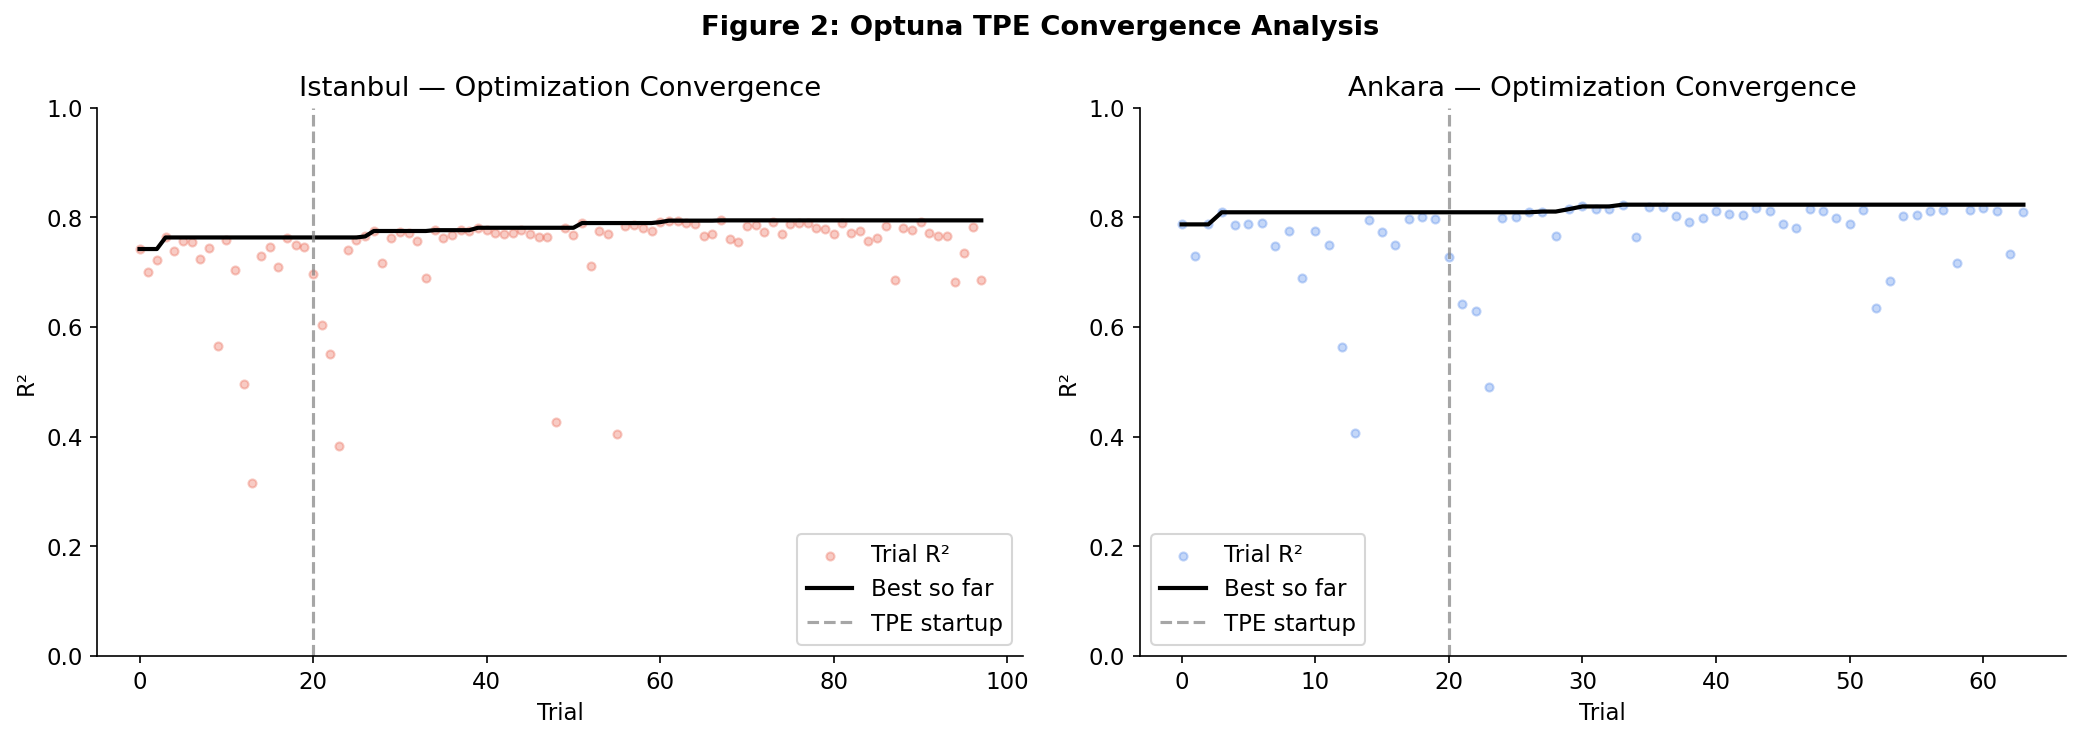

In [16]:
# ── 4.3 Convergence Analizi Görseli (Makale Figure 2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (city, color) in zip(axes, [('Istanbul', '#E8553E'), ('Ankara', '#3E7BE8')]):
    hist = trial_histories[city]
    trials = [h['trial'] for h in hist]
    values = [h['value'] for h in hist]
    bests  = [h['best'] for h in hist]
    
    ax.scatter(trials, values, alpha=0.3, s=15, color=color, label='Trial R²')
    ax.plot(trials, bests, color='black', linewidth=2, label='Best so far')
    ax.axvline(x=20, color='gray', linestyle='--', alpha=0.7, label='TPE startup')
    ax.set_title(f'{city} — Optimization Convergence')
    ax.set_xlabel('Trial')
    ax.set_ylabel('R²')
    ax.legend()
    ax.set_ylim(0, 1)

plt.suptitle('Figure 2: Optuna TPE Convergence Analysis', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig2_convergence.png', bbox_inches='tight')
plt.show()

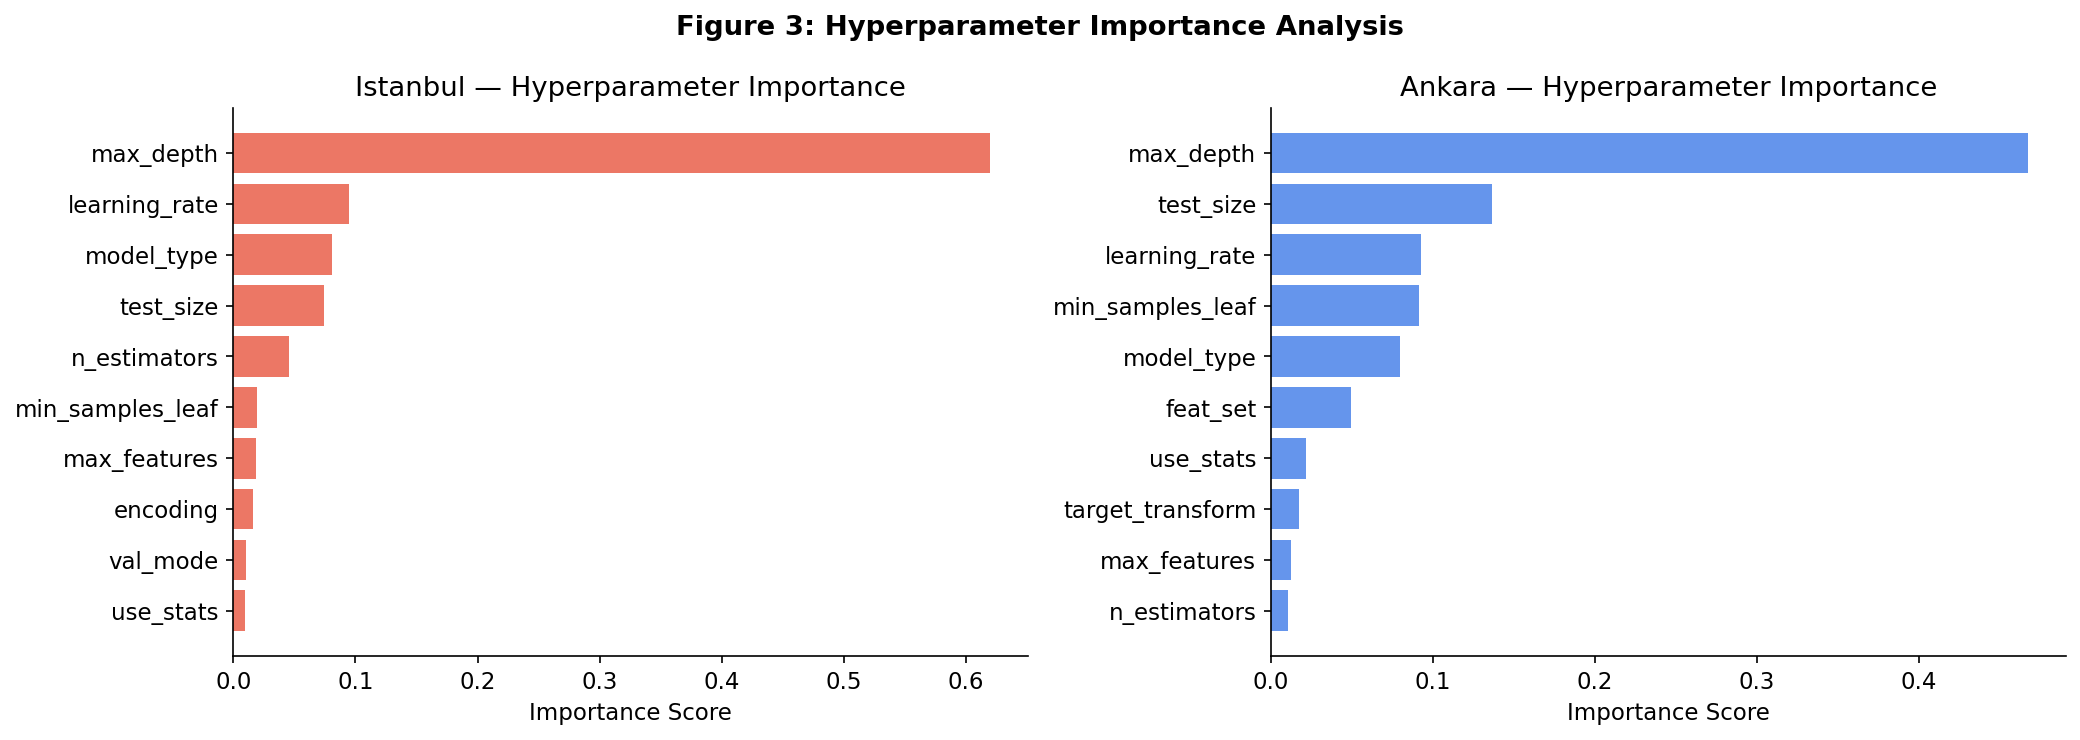

=== Hyperparameter Importance Karşılaştırması ===


,Parameter,Istanbul,Ankara
9,max_depth,0.619573,0.467420
12,learning_rate,0.094733,0.092579
3,model_type,0.081019,0.079662
11,test_size,0.073951,0.136274
10,n_estimators,0.045628,0.010732
6,min_samples_leaf,0.019208,0.091416
1,max_features,0.018945,0.012398
2,encoding,0.016019,0.009439
4,val_mode,0.010774,0.004737
7,use_stats,0.009907,0.021799


In [17]:
# ── 4.4 Hyperparameter Importance (Makale Figure 3)

try:
    from optuna.importance import get_param_importances
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    importance_results = {}
    
    for ax, city in zip(axes, ['Istanbul', 'Ankara']):
        importances = get_param_importances(studies[city])
        importance_results[city] = importances
        
        params_sorted = list(importances.keys())[:10]
        values_sorted = [importances[p] for p in params_sorted]
        
        colors_bar = ['#E8553E' if city == 'Istanbul' else '#3E7BE8'] * len(params_sorted)
        ax.barh(params_sorted[::-1], values_sorted[::-1], color=colors_bar, alpha=0.8)
        ax.set_title(f'{city} — Hyperparameter Importance')
        ax.set_xlabel('Importance Score')
    
    plt.suptitle('Figure 3: Hyperparameter Importance Analysis', fontweight='bold')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / 'fig3_param_importance.png', bbox_inches='tight')
    plt.show()
    
    # Şehirler arası kıyaslama tablosu
    all_params = set(importance_results['Istanbul']) | set(importance_results['Ankara'])
    imp_df = pd.DataFrame({
        'Parameter': list(all_params),
        'Istanbul': [importance_results['Istanbul'].get(p, 0) for p in all_params],
        'Ankara':   [importance_results['Ankara'].get(p, 0) for p in all_params],
    }).sort_values('Istanbul', ascending=False)
    
    print('=== Hyperparameter Importance Karşılaştırması ===')
    display(imp_df)
    imp_df.to_csv(RESULTS_DIR / 'table3_param_importance.csv', index=False)

except Exception as e:
    print(f'Importance analysis skipped: {e}')

---
## 5. Faz 4 — Cross-City Transfer (Özgün Katkı 1)

In [18]:
# ── 5.1 Warm-Start Deneyi
# İstanbul'da optimize edilen trial'lar, Ankara optimizasyonuna başlangıç noktası olarak verilir.
# Kaç trial'da aynı performansa ulaşıyor? → Arama verimliliği

def run_warmstart_study(source_study, target_df, city_name, n_trials=N_OPTUNA_TRIALS):
    """
    source_study'den en iyi trial'ları alıp target_df üzerinde
    warm-start ile yeni çalışma başlatır.
    """
    # En iyi 5 trial'ı al ve enqueue et
    top_trials = sorted(
        [t for t in source_study.trials if t.value is not None],
        key=lambda t: t.value, reverse=True
    )[:5]
    
    sampler = optuna.samplers.TPESampler(
        seed=RANDOM_SEED,
        n_startup_trials=10,  # Warm-start: daha az random trial
        multivariate=True
    )
    
    warm_study = optuna.create_study(
        direction='maximize',
        sampler=sampler,
        study_name=f'housing_{city_name}_warmstart'
    )
    
    # Kaynak çalışmadan en iyi parametreleri enqueue et
    for trial in top_trials:
        warm_study.enqueue_trial(trial.params)
    
    def callback(study, trial):
        if trial.number % 10 == 0 or trial.value == study.best_value:
            print(f'  [WarmStart-{city_name}] Trial {trial.number:3d} | R²={trial.value:.4f} | Best={study.best_value:.4f}')
    
    warm_study.optimize(
        make_objective(target_df), 
        n_trials=n_trials,
        callbacks=[callback]
    )
    return warm_study


print('Istanbul → Ankara warm-start starting...')
df_ankara = df[df['city'] == 'Ankara'].copy().reset_index(drop=True)
warm_study_ankara = run_warmstart_study(
    source_study=studies['Istanbul'],
    target_df=df_ankara,
    city_name='Ankara'
)
studies['Ankara_WarmStart'] = warm_study_ankara

Istanbul → Ankara warm-start starting...
  [WarmStart-Ankara] Trial   0 | R²=0.8048 | Best=0.8048
  [WarmStart-Ankara] Trial   1 | R²=0.8114 | Best=0.8114
  [WarmStart-Ankara] Trial   2 | R²=0.8122 | Best=0.8122
  [WarmStart-Ankara] Trial   3 | R²=0.8142 | Best=0.8142
  [WarmStart-Ankara] Trial  10 | R²=0.7842 | Best=0.8142
  [WarmStart-Ankara] Trial  20 | R²=0.7943 | Best=0.8142
  [WarmStart-Ankara] Trial  30 | R²=0.7935 | Best=0.8142
  [WarmStart-Ankara] Trial  35 | R²=0.8159 | Best=0.8159
  [WarmStart-Ankara] Trial  40 | R²=0.7805 | Best=0.8159
  [WarmStart-Ankara] Trial  42 | R²=0.8165 | Best=0.8165
  [WarmStart-Ankara] Trial  50 | R²=0.8037 | Best=0.8165
  [WarmStart-Ankara] Trial  60 | R²=0.8022 | Best=0.8165
  [WarmStart-Ankara] Trial  62 | R²=0.8180 | Best=0.8180
  [WarmStart-Ankara] Trial  70 | R²=0.8152 | Best=0.8180
  [WarmStart-Ankara] Trial  80 | R²=0.8093 | Best=0.8180
  [WarmStart-Ankara] Trial  89 | R²=0.8208 | Best=0.8208
  [WarmStart-Ankara] Trial  90 | R²=0.8128 | Be

Transfer efficiency: Warm-start reached cold-start final at trial 196
Saving: ~104 trials (35%)


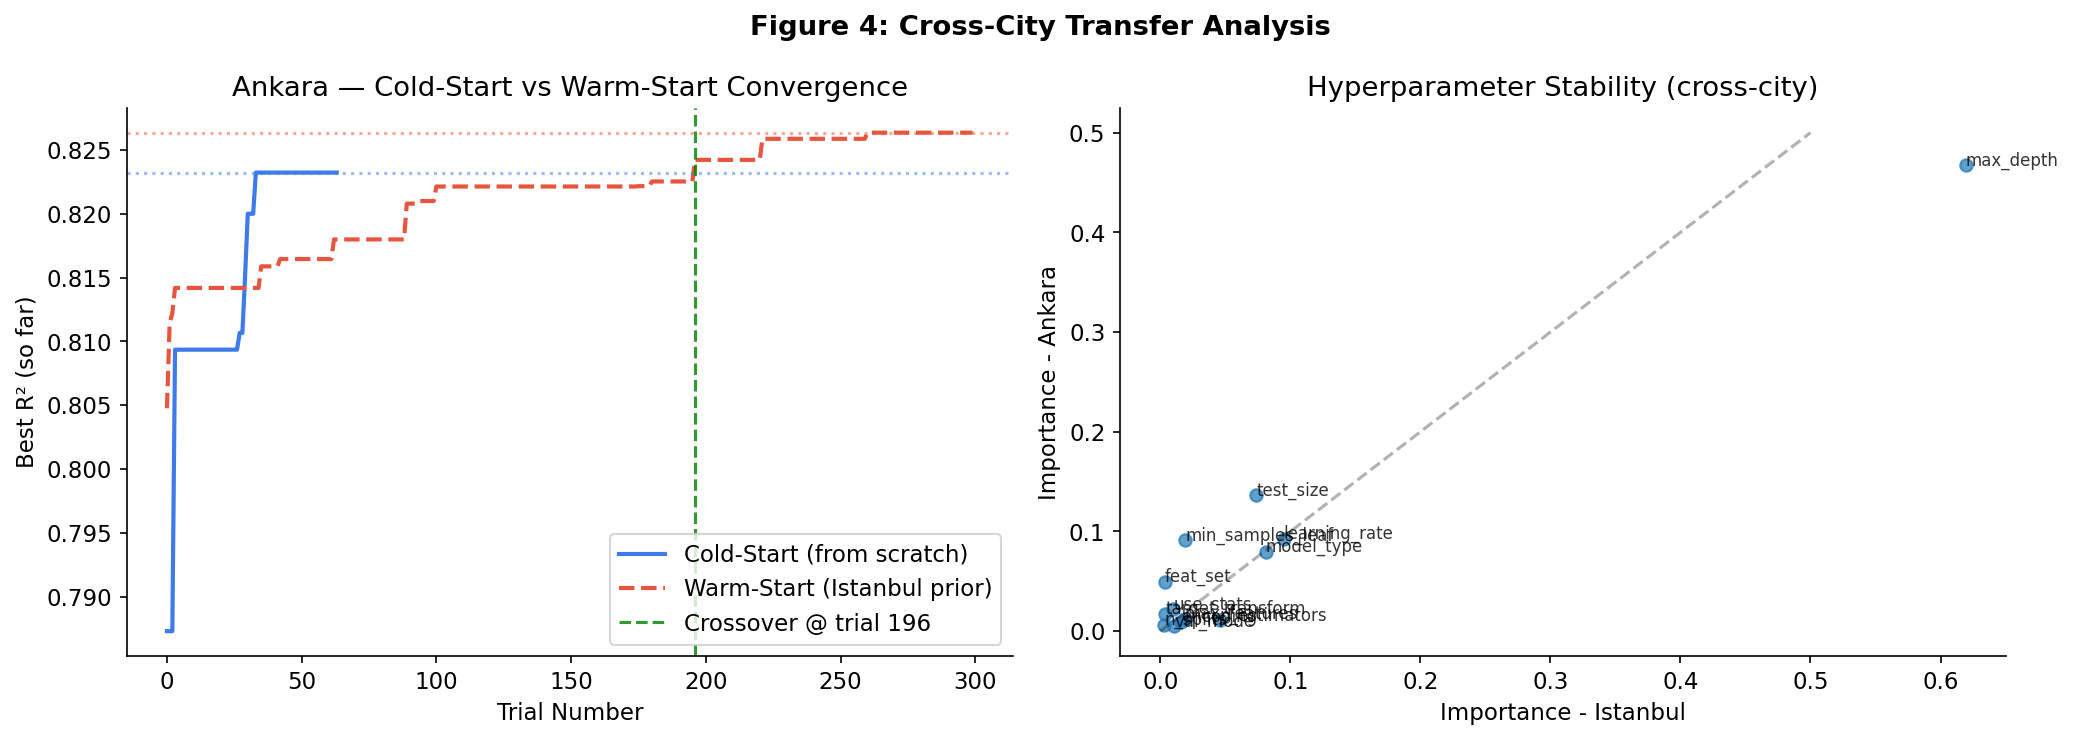

In [19]:
# ── 5.2 Transfer Karşılaştırma Görseli (Makale Figure 4)

def get_best_curve(study):
    """Returns the running best value after each trial."""
    best_so_far = []
    current_best = -np.inf
    for t in study.trials:
        if t.value is not None:
            current_best = max(current_best, t.value)
        best_so_far.append(current_best)
    return best_so_far

has_warmstart = 'Ankara_WarmStart' in studies

ankara_cold = get_best_curve(studies['Ankara'])
ankara_warm = get_best_curve(studies['Ankara_WarmStart']) if has_warmstart else None

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Convergence comparison
ax = axes[0]
ax.plot(ankara_cold, label='Cold-Start (from scratch)', color='#3E7BE8', linewidth=2)

if ankara_warm is not None:
    ax.plot(ankara_warm, label='Warm-Start (Istanbul prior)', color='#E8553E', linewidth=2, linestyle='--')
    ax.axhline(y=max(ankara_warm), color='#E8553E', linestyle=':', alpha=0.5)
    cold_final = max(ankara_cold)
    warm_crossover = next(
        (i for i, v in enumerate(ankara_warm) if v >= cold_final), len(ankara_warm)
    )
    ax.axvline(x=warm_crossover, color='green', linestyle='--', alpha=0.8,
               label=f'Crossover @ trial {warm_crossover}')
    print(f'Transfer efficiency: Warm-start reached cold-start final at trial {warm_crossover}')
    print(f'Saving: ~{N_OPTUNA_TRIALS - warm_crossover} trials ({(N_OPTUNA_TRIALS-warm_crossover)/N_OPTUNA_TRIALS*100:.0f}%)')
else:
    print('Warm-start study not available -- showing cold-start only.')
    print('(Run the "5.1 Warm-Start" cell first to enable full comparison)')

ax.axhline(y=max(ankara_cold), color='#3E7BE8', linestyle=':', alpha=0.5)
ax.set_title('Ankara — Cold-Start vs Warm-Start Convergence')
ax.set_xlabel('Trial Number')
ax.set_ylabel('Best R² (so far)')
ax.legend()

# Right: Parameter stability across cities
ax2 = axes[1]
if 'Ankara' in importance_results and 'Istanbul' in importance_results:
    common = set(importance_results['Istanbul']) & set(importance_results['Ankara'])
    ist_vals = [importance_results['Istanbul'][p] for p in common]
    ank_vals = [importance_results['Ankara'][p] for p in common]
    ax2.scatter(ist_vals, ank_vals, alpha=0.7)
    for p, x, y in zip(common, ist_vals, ank_vals):
        ax2.annotate(p, (x, y), fontsize=8, alpha=0.8)
    ax2.plot([0, 0.5], [0, 0.5], 'k--', alpha=0.3)
    ax2.set_xlabel('Importance - Istanbul')
    ax2.set_ylabel('Importance - Ankara')
    ax2.set_title('Hyperparameter Stability (cross-city)')

plt.suptitle('Figure 4: Cross-City Transfer Analysis', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig4_transfer.png', bbox_inches='tight')
plt.show()


---
## 6. Faz 5 — SHAP Explainability (Özgün Katkı 2)

In [20]:
# ── 6.1 SHAP Kurulumu & Hesaplama
try:
    import shap
    SHAP_AVAILABLE = True
    print('SHAP version:', shap.__version__)
except ImportError:
    SHAP_AVAILABLE = False
    print('SHAP kurulu değil. Kurmak için: pip install shap')

SHAP version: 0.51.0


In [21]:
# ── 6.2 Her Şehir İçin En İyi Model ile SHAP

shap_results = {}

if SHAP_AVAILABLE:
    for city in ['Istanbul', 'Ankara']:
        print(f'\n{city} SHAP analizi...')
        
        # En iyi trial'dan model ve parametreleri al
        best_trial = studies[city].best_trial
        df_city = df[df['city'] == city].copy().reset_index(drop=True)
        
        # Tüm veriyle train et (SHAP için)
        best_params = best_trial.params
        r2, best_model, enc_maps = run_experiment(df_city, {
            **best_params,
            'val_mode': 'split',
            'test_size': 0.2
        })
        
        # Feature matrisini oluştur
        X_all, feat_names, _ = build_features(
            df_city,
            encoding=best_params.get('encoding', 'frequency'),
            feat_set=best_params.get('feat_set', 'extended'),
            use_stats=best_params.get('use_stats', True),
            fit=True
        )
        
        # SHAP değerlerini hesapla (büyük veri için sample)
        sample_size = min(2000, len(X_all))
        X_sample = X_all.sample(sample_size, random_state=RANDOM_SEED)
        
        explainer = shap.TreeExplainer(best_model)
        shap_values = explainer.shap_values(X_sample)
        
        shap_results[city] = {
            'shap_values': shap_values,
            'X_sample': X_sample,
            'feat_names': feat_names,
            'model': best_model
        }
        
        print(f'  {city} SHAP tamamlandı. Sample: {sample_size}')
else:
    print('SHAP analizi atlandı.')


Istanbul SHAP analizi...
  Istanbul SHAP tamamlandı. Sample: 2000

Ankara SHAP analizi...
  Ankara SHAP tamamlandı. Sample: 2000


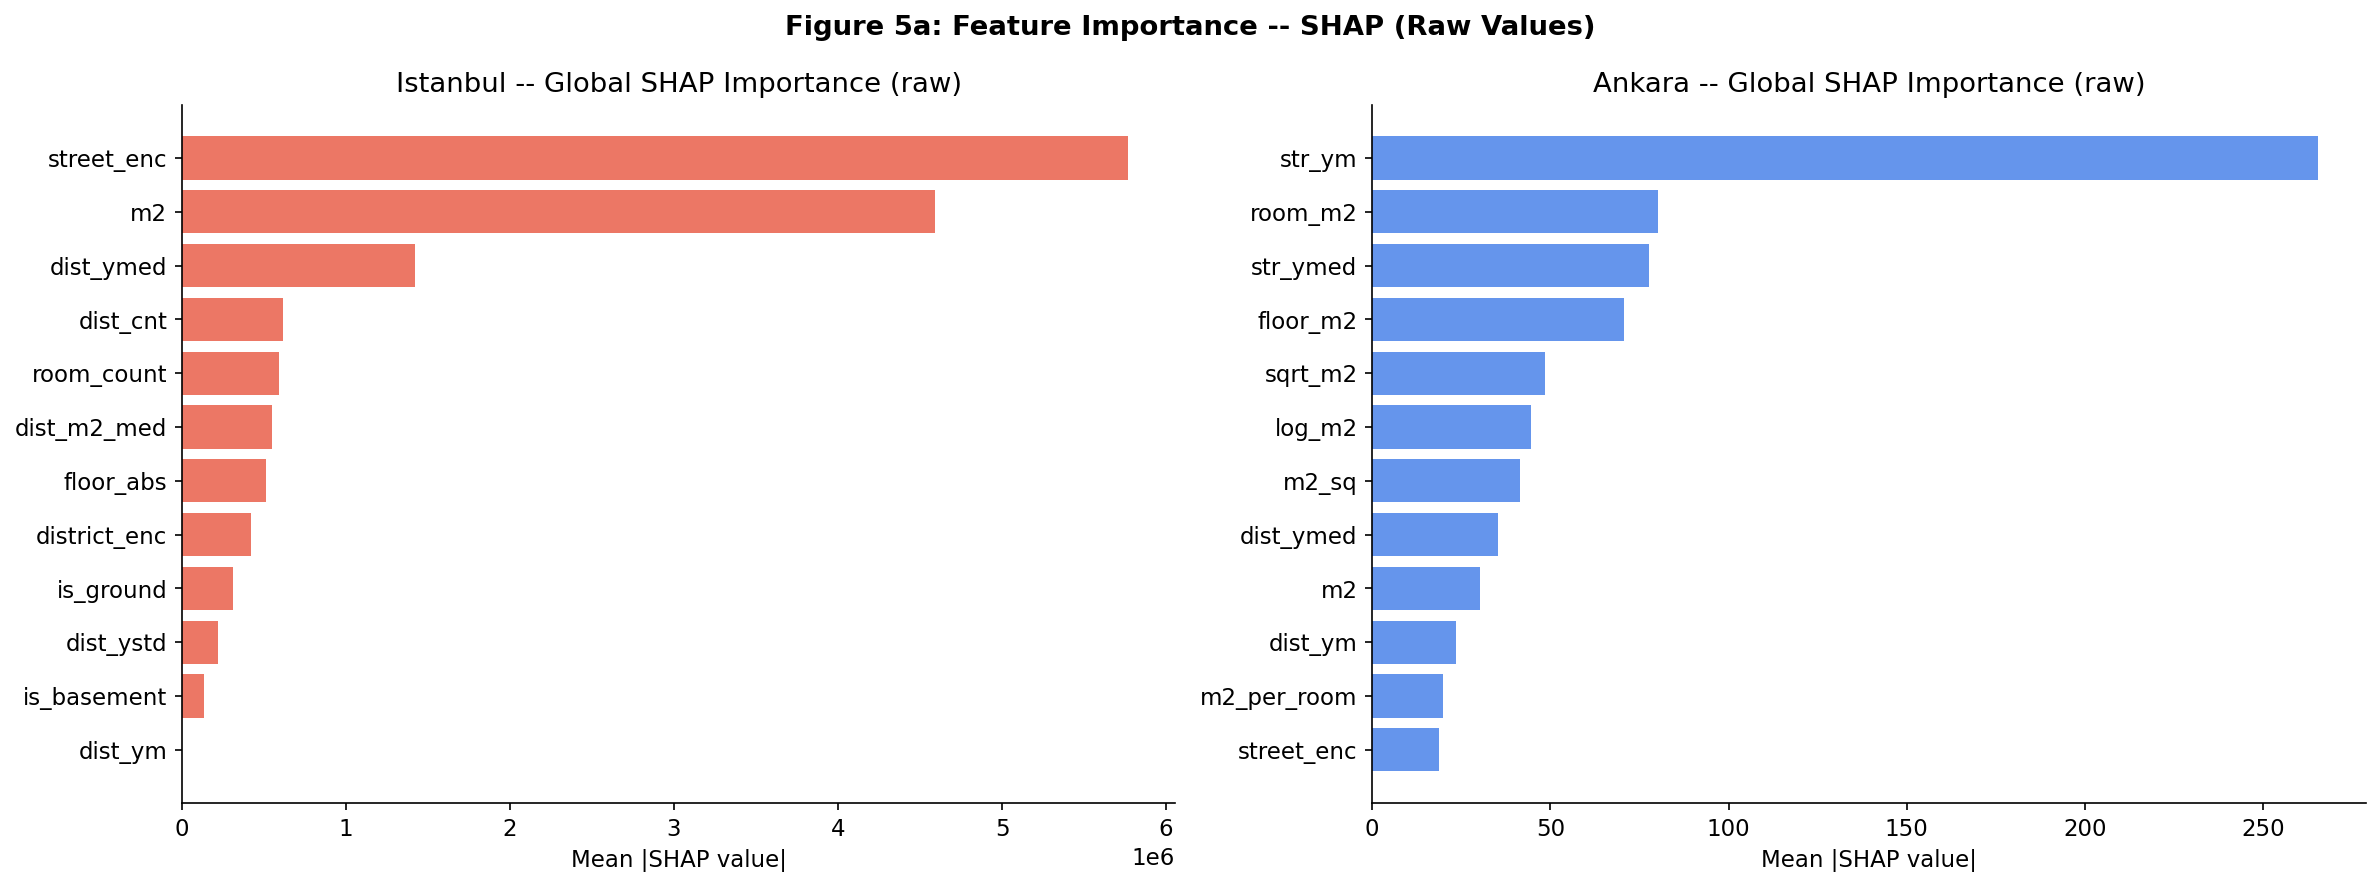

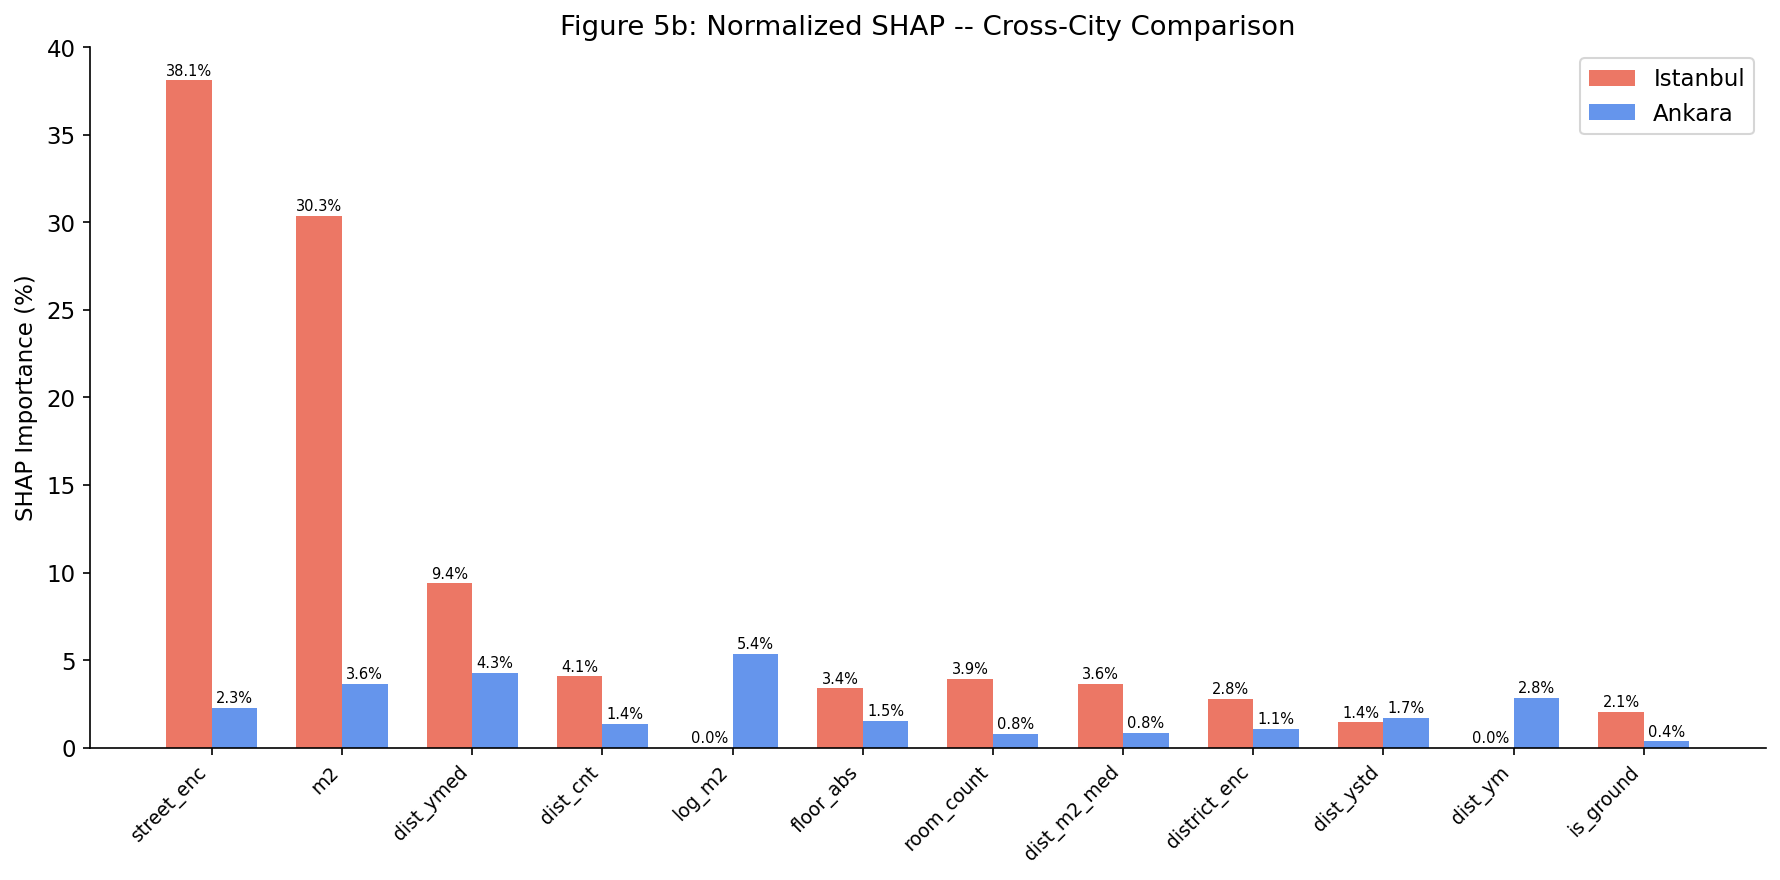

=== TABLE 4: SHAP Importance Comparison (Normalized) ===


,Feature,Istanbul_raw,Istanbul_pct,Ankara_raw,Ankara_pct,Diff_pct
0,street_enc,5768054.17,38.10,18.70,2.26,35.84
1,m2,4593589.90,30.34,30.22,3.65,26.70
2,dist_ymed,1420872.05,9.39,35.29,4.26,5.13
3,dist_cnt,616649.96,4.07,11.29,1.36,2.71
4,room_count,592070.57,3.91,6.48,0.78,3.13
5,dist_m2_med,550921.18,3.64,7.01,0.85,2.79
6,floor_abs,512308.36,3.38,12.67,1.53,1.85
7,district_enc,419473.26,2.77,9.04,1.09,1.68
8,is_ground,311204.94,2.06,3.04,0.37,1.69
9,dist_ystd,218626.71,1.44,14.04,1.69,0.25



Istanbul top-3: street_enc (38.1%), m2 (30.3%), dist_ymed (9.4%)
Ankara top-3: str_ym (32.0%), room_m2 (9.7%), str_ymed (9.4%)


In [22]:
# -- 6.3 Global SHAP Karsilastirmasi (Makale Figure 5)
# Ham SHAP + Normalize edilmis SHAP (yuzde) -- sehirler arasi karsilastirma icin

if SHAP_AVAILABLE and shap_results:
    # -- Ham SHAP onemi hesapla
    importance_shap = {}
    importance_shap_pct = {}

    for city in ['Istanbul', 'Ankara']:
        res = shap_results[city]
        sv   = res['shap_values']
        feat = res['feat_names']

        mean_abs_shap = np.abs(sv).mean(axis=0)
        total_shap = mean_abs_shap.sum()

        importance_shap[city] = dict(zip(feat, mean_abs_shap))
        importance_shap_pct[city] = dict(zip(feat, (mean_abs_shap / total_shap) * 100))

    # -- Figure 5a: Ham SHAP
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, city in zip(axes, ['Istanbul', 'Ankara']):
        vals = importance_shap[city]
        sorted_feats = sorted(vals.items(), key=lambda x: x[1])[-12:]
        names = [f[0] for f in sorted_feats]
        scores = [f[1] for f in sorted_feats]
        color = '#E8553E' if city == 'Istanbul' else '#3E7BE8'
        ax.barh(names, scores, color=color, alpha=0.8)
        ax.set_title(f'{city} -- Global SHAP Importance (raw)')
        ax.set_xlabel('Mean |SHAP value|')

    plt.suptitle('Figure 5a: Feature Importance -- SHAP (Raw Values)', fontweight='bold')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / 'fig5_shap_global.png', bbox_inches='tight')
    plt.show()

    # -- Figure 5b: Normalize SHAP (yuzde) -- sehirler arasi karsilastirma
    common_feats = sorted(
        set(importance_shap_pct['Istanbul']) & set(importance_shap_pct['Ankara']),
        key=lambda f: importance_shap_pct['Istanbul'].get(f, 0) + importance_shap_pct['Ankara'].get(f, 0),
        reverse=True
    )[:12]

    fig, ax = plt.subplots(figsize=(12, 6))
    x_pos = np.arange(len(common_feats))
    bar_width = 0.35

    ist_vals = [importance_shap_pct['Istanbul'].get(f, 0) for f in common_feats]
    ank_vals = [importance_shap_pct['Ankara'].get(f, 0) for f in common_feats]

    ax.bar(x_pos - bar_width/2, ist_vals, bar_width, color='#E8553E', alpha=0.8, label='Istanbul')
    ax.bar(x_pos + bar_width/2, ank_vals, bar_width, color='#3E7BE8', alpha=0.8, label='Ankara')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(common_feats, rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('SHAP Importance (%)')
    ax.set_title('Figure 5b: Normalized SHAP -- Cross-City Comparison')
    ax.legend()

    for i, (ist, ank) in enumerate(zip(ist_vals, ank_vals)):
        ax.text(i - bar_width/2, ist + 0.3, f'{ist:.1f}%', ha='center', fontsize=7)
        ax.text(i + bar_width/2, ank + 0.3, f'{ank:.1f}%', ha='center', fontsize=7)

    plt.tight_layout()
    plt.savefig(RESULTS_DIR / 'fig5b_shap_normalized.png', bbox_inches='tight')
    plt.show()

    # -- Tablo 4: Karsilastirma tablosu (ham + normalize)
    all_feats = sorted(
        set(importance_shap['Istanbul']) | set(importance_shap['Ankara']),
        key=lambda f: importance_shap_pct['Istanbul'].get(f, 0),
        reverse=True
    )
    shap_comparison = pd.DataFrame({
        'Feature': all_feats,
        'Istanbul_raw': [importance_shap['Istanbul'].get(f, 0) for f in all_feats],
        'Istanbul_pct': [importance_shap_pct['Istanbul'].get(f, 0) for f in all_feats],
        'Ankara_raw':   [importance_shap['Ankara'].get(f, 0) for f in all_feats],
        'Ankara_pct':   [importance_shap_pct['Ankara'].get(f, 0) for f in all_feats],
    })
    shap_comparison['Diff_pct'] = (shap_comparison['Istanbul_pct'] - shap_comparison['Ankara_pct']).abs()
    shap_comparison = shap_comparison.sort_values('Istanbul_pct', ascending=False)

    print('=== TABLE 4: SHAP Importance Comparison (Normalized) ===')
    display(shap_comparison.round(2))
    shap_comparison.to_csv(RESULTS_DIR / 'table4_shap_comparison.csv', index=False)

    print()
    for city in ['Istanbul', 'Ankara']:
        top3 = sorted(importance_shap_pct[city].items(), key=lambda x: x[1], reverse=True)[:3]
        print(f'{city} top-3: {", ".join(f"{k} ({v:.1f}%)" for k,v in top3)}')


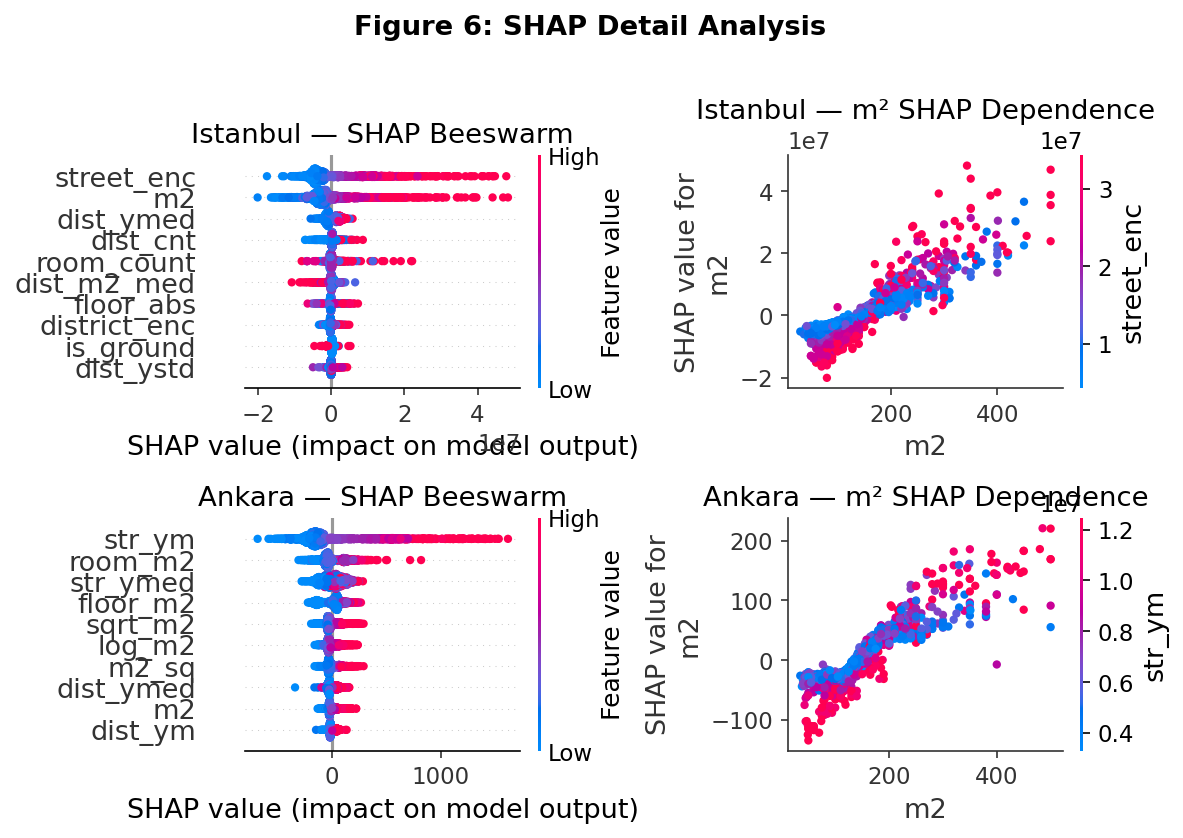

In [23]:
# ── 6.4 SHAP Beeswarm + Dependence Plots (Makale Figure 6)

if SHAP_AVAILABLE and shap_results:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    for row, city in enumerate(['Istanbul', 'Ankara']):
        res = shap_results[city]
        sv   = res['shap_values']
        X_s  = res['X_sample']
        feat = res['feat_names']
        
        # Beeswarm
        plt.sca(axes[row, 0])
        shap.summary_plot(sv, X_s, feature_names=feat, show=False, max_display=10)
        axes[row, 0].set_title(f'{city} — SHAP Beeswarm')
        
        # m2 dependence plot
        plt.sca(axes[row, 1])
        if 'm2' in feat:
            m2_idx = feat.index('m2')
            shap.dependence_plot('m2', sv, X_s, feature_names=feat, show=False, ax=axes[row, 1])
            axes[row, 1].set_title(f'{city} — m² SHAP Dependence')
    
    plt.suptitle('Figure 6: SHAP Detail Analysis', fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / 'fig6_shap_detail.png', bbox_inches='tight')
    plt.show()

---
## 7. Faz 6 — İstatistiksel Doğrulama (Makale Tablo 5)

In [24]:
# ── 7.1 Ablation Study
# Her pipeline bileşeninin katkısını izole ölç

def run_ablation(df_city, base_params, n_seeds=3):
    """
    Base pipeline'dan tek tek bileşen kaldırarak etkisini ölçer.
    """
    ablation_configs = {
        'Full Pipeline':         base_params,
        'No Stats Features':     {**base_params, 'use_stats': False},
        'No Feature Eng (basic)': {**base_params, 'feat_set': 'basic'},
        'No Target Transform':   {**base_params, 'target_transform': 'none'},
        'Label Encoding':        {**base_params, 'encoding': 'label'},
    }
    
    results = {}
    for name, params in ablation_configs.items():
        scores = []
        for seed in range(n_seeds):
            try:
                exp_params = {**params, 'val_mode': 'kfold', 'n_splits': 5}
                r2, _, _ = run_experiment(df_city, exp_params, random_seed=RANDOM_SEED + seed)
                scores.append(r2)
            except:
                pass
        results[name] = {'mean': np.mean(scores), 'std': np.std(scores)}
        print(f'  {name}: R²={results[name]["mean"]:.4f} ±{results[name]["std"]:.4f}')
    
    return results

print('=== Ablation Study ===')
ablation_results = {}

for city in ['Istanbul', 'Ankara']:
    print(f'\n{city}:')
    best_params = studies[city].best_params
    df_city = df[df['city'] == city].copy().reset_index(drop=True)
    ablation_results[city] = run_ablation(df_city, best_params)

=== Ablation Study ===

Istanbul:
  Full Pipeline: R²=0.7618 ±0.0006
  No Stats Features: R²=0.7615 ±0.0019
  No Feature Eng (basic): R²=0.7618 ±0.0006
  No Target Transform: R²=0.7618 ±0.0006
  Label Encoding: R²=0.7559 ±0.0020

Ankara:
  Full Pipeline: R²=0.8234 ±0.0013
  No Stats Features: R²=0.8027 ±0.0017
  No Feature Eng (basic): R²=0.8078 ±0.0020
  No Target Transform: R²=0.8209 ±0.0017
  Label Encoding: R²=0.8230 ±0.0007


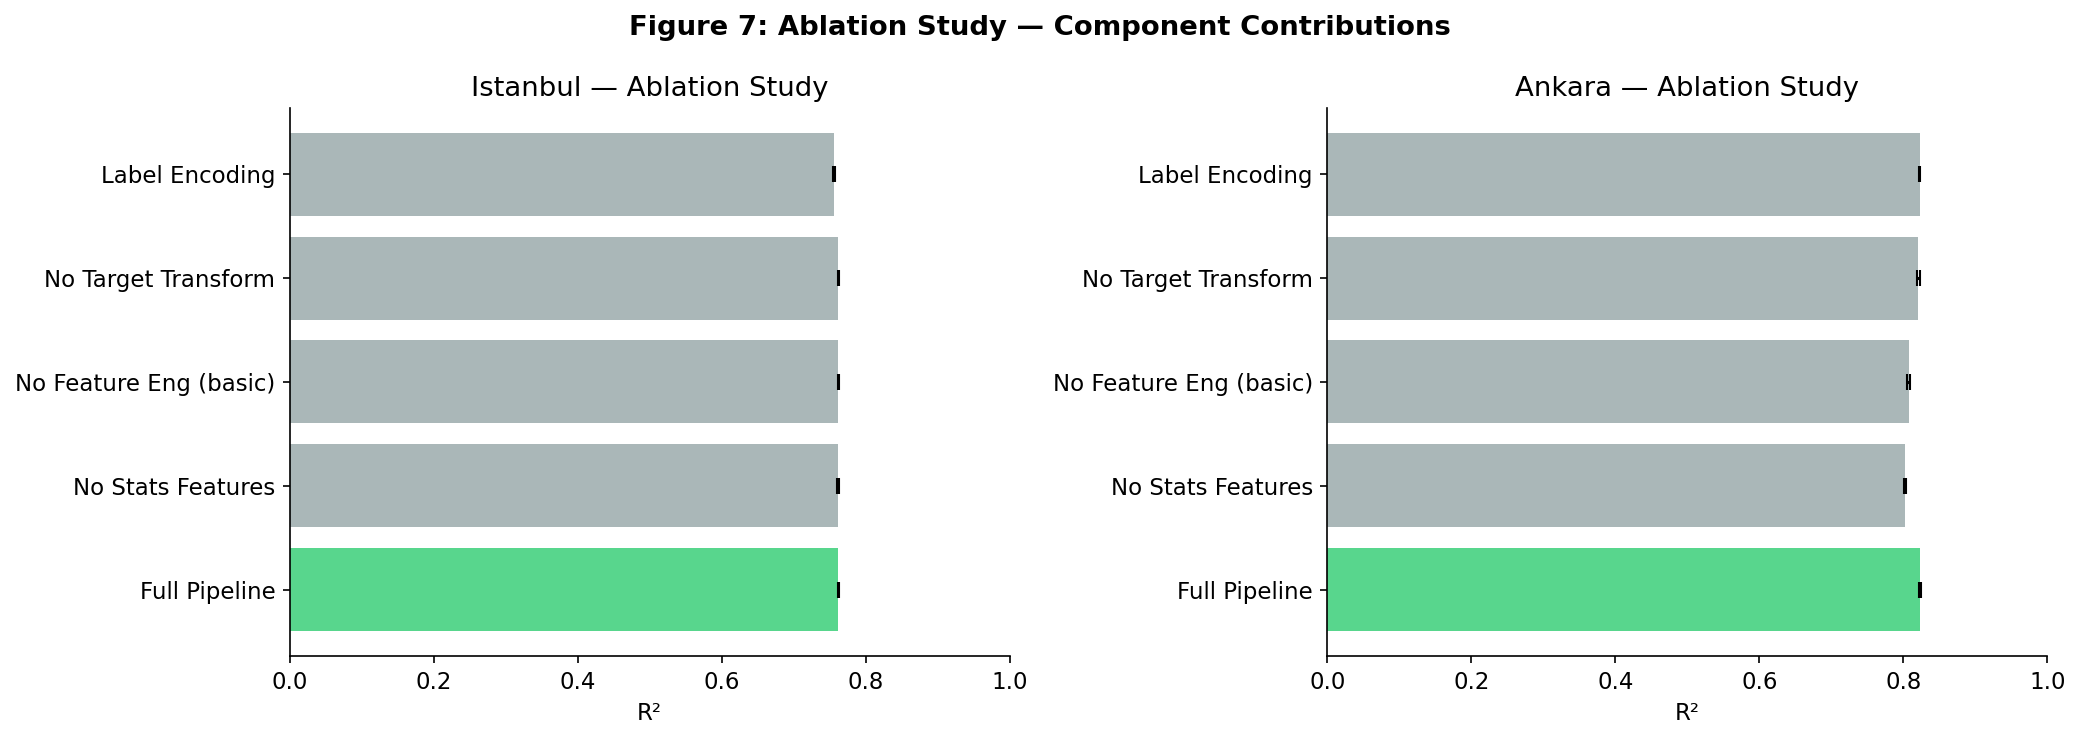

=== TABLO 5: Ablation Study ===


,City,Configuration,R² Mean,R² Std
0,Istanbul,Full Pipeline,0.7618,±0.0006
1,Istanbul,No Stats Features,0.7615,±0.0019
2,Istanbul,No Feature Eng (basic),0.7618,±0.0006
3,Istanbul,No Target Transform,0.7618,±0.0006
4,Istanbul,Label Encoding,0.7559,±0.0020
5,Ankara,Full Pipeline,0.8234,±0.0013
6,Ankara,No Stats Features,0.8027,±0.0017
7,Ankara,No Feature Eng (basic),0.8078,±0.0020
8,Ankara,No Target Transform,0.8209,±0.0017
9,Ankara,Label Encoding,0.8230,±0.0007


In [25]:
# ── 7.2 Ablation Tablo & Görsel (Makale Tablo 5 + Figure 7)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, city in zip(axes, ['Istanbul', 'Ankara']):
    res = ablation_results[city]
    names  = list(res.keys())
    means  = [res[n]['mean'] for n in names]
    stds   = [res[n]['std'] for n in names]
    
    colors_bar = ['#2ecc71' if n == 'Full Pipeline' else '#95a5a6' for n in names]
    ax.barh(names, means, xerr=stds, color=colors_bar, alpha=0.8, capsize=4)
    ax.set_title(f'{city} — Ablation Study')
    ax.set_xlabel('R²')
    ax.set_xlim(0, 1)

plt.suptitle('Figure 7: Ablation Study — Component Contributions', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig7_ablation.png', bbox_inches='tight')
plt.show()

# Tablo formatı
ablation_rows = []
for city in ['Istanbul', 'Ankara']:
    for config, metrics in ablation_results[city].items():
        ablation_rows.append({
            'City': city, 'Configuration': config,
            'R² Mean': f"{metrics['mean']:.4f}",
            'R² Std': f"±{metrics['std']:.4f}"
        })

tablo5 = pd.DataFrame(ablation_rows)
print('=== TABLO 5: Ablation Study ===')
display(tablo5)
tablo5.to_csv(RESULTS_DIR / 'table5_ablation.csv', index=False)

In [26]:
# -- 7.3 Istatistiksel Significance Testleri

from scipy import stats

def statistical_comparison(model_scores_dict, alpha=0.05):
    names = list(model_scores_dict.keys())
    n = len(names)
    pval_matrix = np.ones((n, n))
    
    for i in range(n):
        for j in range(i+1, n):
            scores_i = model_scores_dict[names[i]]
            scores_j = model_scores_dict[names[j]]
            min_len = min(len(scores_i), len(scores_j))
            if min_len >= 5:
                _, p = stats.wilcoxon(scores_i[:min_len], scores_j[:min_len])
                p_adjusted = min(p * (n * (n-1) / 2), 1.0)
                pval_matrix[i, j] = p_adjusted
                pval_matrix[j, i] = p_adjusted
    
    return pd.DataFrame(pval_matrix, index=names, columns=names)

print(f'Istatistiksel testler: N_BOOTSTRAP={N_BOOTSTRAP}')
print()

for city in ['Istanbul', 'Ankara']:
    print(f'=== {city} -- Wilcoxon Pairwise Comparison ===')
    
    sub = df[df['city'] == city].copy().reset_index(drop=True)
    X, _, _ = build_features(sub, encoding='frequency', feat_set='extended', use_stats=True)
    y = sub['Price']
    
    bootstrap_models = {
        'OLS':   LinearRegression(),
        'Ridge': Ridge(alpha=1.0),
        'RF':    RandomForestRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1),
        'HGB':   HistGradientBoostingRegressor(max_iter=200, random_state=RANDOM_SEED),
    }
    if LGB_AVAILABLE:
        bootstrap_models['LightGBM'] = lgb.LGBMRegressor(
            n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)
    
    model_scores = {}
    for name, model in bootstrap_models.items():
        scores = []
        for seed in range(N_BOOTSTRAP):
            kf = KFold(n_splits=5, shuffle=True, random_state=seed)
            fold_scores = []
            for tr_idx, val_idx in kf.split(X):
                X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
                y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
                y_tr_t = np.log1p(y_tr)
                model.fit(X_tr, y_tr_t)
                pred = np.expm1(model.predict(X_val))
                fold_scores.append(r2_score(y_val, pred))
            scores.append(np.mean(fold_scores))
        model_scores[name] = scores
        print(f'  {name}: R2={np.mean(scores):.4f} +/-{np.std(scores):.4f}')
    
    pval_df = statistical_comparison(model_scores)
    print()
    print('  Bonferroni-adjusted p-value matrix:')
    print(pval_df.round(4).to_string())
    print()
    
    score_matrix = np.array(list(model_scores.values()))
    if score_matrix.shape[0] >= 3 and score_matrix.shape[1] >= 3:
        stat_f, p_f = stats.friedmanchisquare(*[model_scores[m] for m in model_scores])
        print(f'  Friedman testi: chi2={stat_f:.4f}, p={p_f:.4e}')
        sig = 'anlamli' if p_f < 0.05 else 'anlamsiz'
        print(f'  --> Modeller arasinda {sig} fark var (alpha=0.05)')
    print()


Istatistiksel testler: N_BOOTSTRAP=30

=== Istanbul -- Wilcoxon Pairwise Comparison ===
  OLS: R2=0.5877 +/-0.0013
  Ridge: R2=0.5885 +/-0.0012
  RF: R2=0.7406 +/-0.0026
  HGB: R2=0.7425 +/-0.0016
  LightGBM: R2=0.7430 +/-0.0020

  Bonferroni-adjusted p-value matrix:
          OLS  Ridge      RF     HGB  LightGBM
OLS       1.0    0.0  0.0000  0.0000    0.0000
Ridge     0.0    1.0  0.0000  0.0000    0.0000
RF        0.0    0.0  1.0000  0.0113    0.0006
HGB       0.0    0.0  0.0113  1.0000    1.0000
LightGBM  0.0    0.0  0.0006  1.0000    1.0000

  Friedman testi: chi2=101.2267, p=5.3910e-21
  --> Modeller arasinda anlamli fark var (alpha=0.05)

=== Ankara -- Wilcoxon Pairwise Comparison ===
  OLS: R2=0.6018 +/-0.0003
  Ridge: R2=0.5913 +/-0.0003
  RF: R2=0.7819 +/-0.0014
  HGB: R2=0.7869 +/-0.0015
  LightGBM: R2=0.7884 +/-0.0011

  Bonferroni-adjusted p-value matrix:
          OLS  Ridge   RF  HGB  LightGBM
OLS       1.0    0.0  0.0  0.0       0.0
Ridge     0.0    1.0  0.0  0.0       0.

In [27]:
# -- 7.4 Price Segment Performance Analysis
# A) Global model -> evaluate by segments
# B) Stratified: train separate model per segment (new)

def segment_performance_global(model, X, y_true, best_params):
    quantiles = pd.qcut(y_true, q=4, labels=['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)'])
    pred = model.predict(X)
    
    tf = best_params.get('target_transform', 'none')
    if tf == 'log1p':   pred = np.expm1(pred)
    elif tf == 'sqrt':  pred = pred ** 2
    elif tf == 'cbrt':  pred = pred ** 3
    pred = np.clip(pred, 0, None)
    
    results_seg = {}
    for q in ['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)']:
        mask = quantiles == q
        if mask.sum() > 10:
            r2 = r2_score(y_true[mask], pred[mask])
            mae = mean_absolute_error(y_true[mask], pred[mask])
            results_seg[q] = {'R2': r2, 'MAE_M': mae/1e6}
    return results_seg


def segment_performance_stratified(df_city, best_params, n_splits=5):
    y_all = df_city['Price']
    quantile_labels = pd.qcut(y_all, q=4, labels=['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)'])
    
    results_seg = {}
    for q in ['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)']:
        mask = quantile_labels == q
        sub = df_city[mask].copy().reset_index(drop=True)
        if len(sub) < 100:
            continue
        
        X, _, _ = build_features(
            sub,
            encoding=best_params.get('encoding', 'target_mean'),
            feat_set=best_params.get('feat_set', 'extended'),
            use_stats=best_params.get('use_stats', True), fit=True)
        y = sub['Price']
        
        tf = best_params.get('target_transform', 'log1p')
        if tf == 'log1p':   y_t = np.log1p(y)
        elif tf == 'sqrt':  y_t = np.sqrt(y.clip(0))
        elif tf == 'cbrt':  y_t = np.cbrt(y)
        else:               y_t = y
        
        mt = best_params.get('model_type', 'hgb')
        if mt == 'hgb':
            model = HistGradientBoostingRegressor(
                max_iter=best_params.get('n_estimators', 200), random_state=RANDOM_SEED)
        elif mt == 'lgbm' and LGB_AVAILABLE:
            model = lgb.LGBMRegressor(
                n_estimators=best_params.get('n_estimators', 200),
                random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)
        else:
            model = RandomForestRegressor(
                n_estimators=best_params.get('n_estimators', 200),
                random_state=RANDOM_SEED, n_jobs=-1)
        
        kf = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)
        r2_scores, mae_scores = [], []
        
        for tr_idx, val_idx in kf.split(X):
            X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
            y_tr_t, y_val = y_t.iloc[tr_idx], y.iloc[val_idx]
            model.fit(X_tr, y_tr_t)
            pred_t = model.predict(X_val)
            
            if tf == 'log1p':   pred = np.expm1(pred_t)
            elif tf == 'sqrt':  pred = pred_t ** 2
            elif tf == 'cbrt':  pred = pred_t ** 3
            else:               pred = pred_t
            pred = np.clip(pred, 0, None)
            
            r2_scores.append(r2_score(y_val, pred))
            mae_scores.append(mean_absolute_error(y_val, pred))
        
        results_seg[q] = {
            'R2': np.mean(r2_scores),
            'R2_std': np.std(r2_scores),
            'MAE_M': np.mean(mae_scores)/1e6}
    return results_seg


seg_results_global = {}
seg_results_stratified = {}

for city in ['Istanbul', 'Ankara']:
    best_params = studies[city].best_params
    df_city = df[df['city'] == city].copy().reset_index(drop=True)
    
    X_all, _, enc_maps = build_features(
        df_city,
        encoding=best_params.get('encoding', 'frequency'),
        feat_set=best_params.get('feat_set', 'extended'),
        use_stats=best_params.get('use_stats', True), fit=True)
    y_all = df_city['Price']
    
    tf = best_params.get('target_transform', 'log1p')
    if tf == 'log1p':   y_t = np.log1p(y_all)
    elif tf == 'sqrt':  y_t = np.sqrt(y_all.clip(0))
    elif tf == 'cbrt':  y_t = np.cbrt(y_all)
    else:               y_t = y_all
    
    mt = best_params.get('model_type', 'hgb')
    if mt == 'hgb':
        seg_model = HistGradientBoostingRegressor(
            max_iter=best_params.get('n_estimators', 200), random_state=RANDOM_SEED)
    elif mt == 'lgbm' and LGB_AVAILABLE:
        seg_model = lgb.LGBMRegressor(
            n_estimators=best_params.get('n_estimators', 200),
            random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)
    else:
        seg_model = RandomForestRegressor(
            n_estimators=best_params.get('n_estimators', 200),
            random_state=RANDOM_SEED, n_jobs=-1)
    
    seg_model.fit(X_all, y_t)
    seg_results_global[city] = segment_performance_global(seg_model, X_all, y_all.values, best_params)
    seg_results_stratified[city] = segment_performance_stratified(df_city, best_params)
    
    print(f'{city} -- Segment Performance:')
    header = f'  {"Segment":<15} {"Global R2":>12} {"Stratified R2":>15} {"Strat. MAE":>12}'
    print(header)
    print(f'  {"-"*15} {"-"*12} {"-"*15} {"-"*12}')
    for seg in ['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)']:
        g_r2 = seg_results_global[city].get(seg, {}).get('R2', float('nan'))
        s_r2 = seg_results_stratified[city].get(seg, {}).get('R2', float('nan'))
        s_mae = seg_results_stratified[city].get(seg, {}).get('MAE_M', float('nan'))
        print(f'  {seg:<15} {g_r2:>12.4f} {s_r2:>15.4f} {s_mae:>10.2f}M TL')


Istanbul -- Segment Performance:
  Segment            Global R2   Stratified R2   Strat. MAE
  --------------- ------------ --------------- ------------
  Q1 (Low)             -3.3011          0.4011       0.53M TL
  Q2                   -5.7184          0.2471       0.55M TL
  Q3                   -1.3089          0.4126       1.34M TL
  Q4 (High)             0.8069          0.6260       7.15M TL
Ankara -- Segment Performance:
  Segment            Global R2   Stratified R2   Strat. MAE
  --------------- ------------ --------------- ------------
  Q1 (Low)              0.3014          0.4345       0.27M TL
  Q2                   -0.7022          0.1777       0.25M TL
  Q3                    0.1118          0.3245       0.40M TL
  Q4 (High)             0.9293          0.7154       1.82M TL


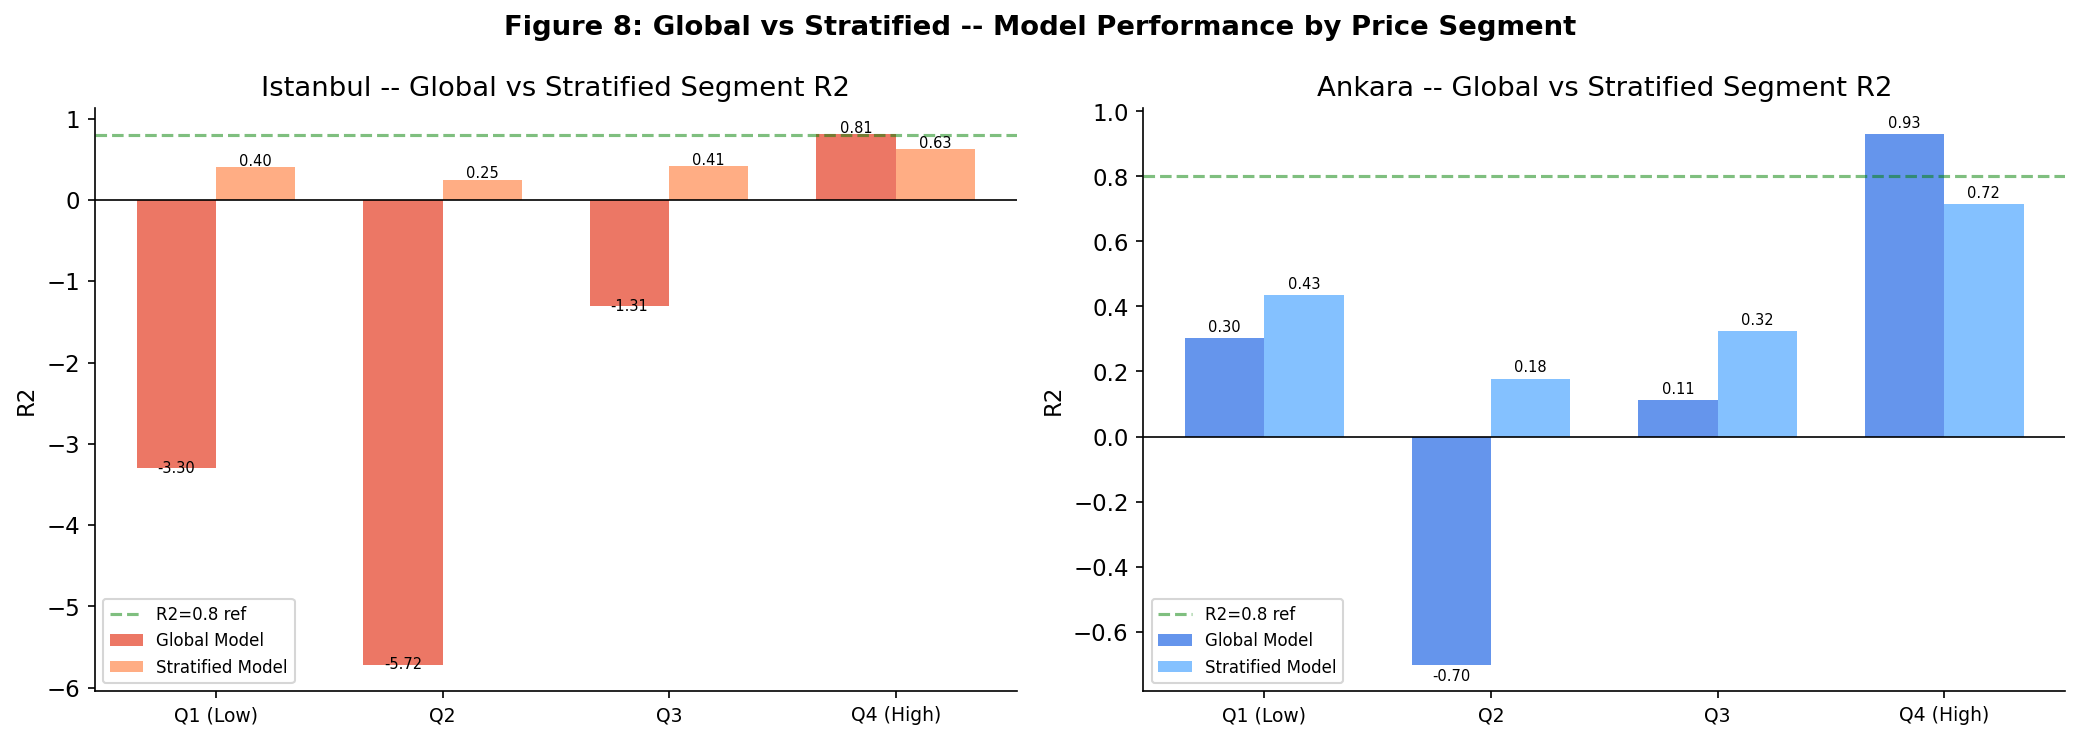

In [28]:
# -- 7.5 Segment Performans Gorseli (Makale Figure 8)
# Global model vs Stratified model karsilastirmasi

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
segments = ['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)']
x_pos = np.arange(len(segments))
bar_width = 0.35

for ax, city in zip(axes, ['Istanbul', 'Ankara']):
    color_g = '#E8553E' if city == 'Istanbul' else '#3E7BE8'
    color_s = '#FF9966' if city == 'Istanbul' else '#66B2FF'

    r2_global = [seg_results_global[city].get(s, {}).get('R2', 0) for s in segments]
    r2_strat  = [seg_results_stratified[city].get(s, {}).get('R2', 0) for s in segments]

    bars1 = ax.bar(x_pos - bar_width/2, r2_global, bar_width,
                   color=color_g, alpha=0.8, label='Global Model')
    bars2 = ax.bar(x_pos + bar_width/2, r2_strat, bar_width,
                   color=color_s, alpha=0.8, label='Stratified Model')

    ax.axhline(y=0, color='black', linewidth=0.8)
    ax.axhline(y=0.8, color='green', linestyle='--', alpha=0.5, label='R2=0.8 ref')
    ax.set_title(f'{city} -- Global vs Stratified Segment R2')
    ax.set_ylabel('R2')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(segments, fontsize=9)
    ax.legend(fontsize=8)

    for i, (g, s) in enumerate(zip(r2_global, r2_strat)):
        y_g = max(g, 0) + 0.02 if g >= 0 else g - 0.05
        y_s = max(s, 0) + 0.02 if s >= 0 else s - 0.05
        ax.text(i - bar_width/2, y_g, f'{g:.2f}', ha='center', fontsize=7)
        ax.text(i + bar_width/2, y_s, f'{s:.2f}', ha='center', fontsize=7)

plt.suptitle('Figure 8: Global vs Stratified -- Model Performance by Price Segment', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig8_segment_performance.png', bbox_inches='tight')
plt.show()


---
## 8. Final Sonuçlar & Makale Özeti

In [29]:
# ── 8.1 Master Sonuç Tablosu (Makale Tablo 3)

print('=== MASTER SONUÇ TABLOSU ===')
print()

for city in ['Istanbul', 'Ankara']:
    best = studies[city].best_trial
    warm = studies.get(f'{city}_WarmStart')
    
    print(f'{city}:')
    print(f'  Cold-Start Best R²:  {studies[city].best_value:.4f}')
    if city == 'Ankara' and 'Ankara_WarmStart' in studies:
        print(f'  Warm-Start Best R²:  {studies["Ankara_WarmStart"].best_value:.4f}')
    print(f'  Best Model Type:     {best.params.get("model_type", "N/A")}')
    print(f'  Best Encoding:       {best.params.get("encoding", "N/A")}')
    print(f'  Best Target TF:      {best.params.get("target_transform", "N/A")}')
    print(f'  Best Feat Set:       {best.params.get("feat_set", "N/A")}')
    print(f'  Use Stats:           {best.params.get("use_stats", "N/A")}')
    print()

# List all output files
print('\nOutput files:')
for f in sorted(RESULTS_DIR.iterdir()):
    print(f'  {f.name}')

=== MASTER SONUÇ TABLOSU ===

Istanbul:
  Cold-Start Best R²:  0.7946
  Best Model Type:     lgbm
  Best Encoding:       target_mean
  Best Target TF:      none
  Best Feat Set:       basic
  Use Stats:           True

Ankara:
  Cold-Start Best R²:  0.8232
  Warm-Start Best R²:  0.8264
  Best Model Type:     gb
  Best Encoding:       ordinal_by_freq
  Best Target TF:      sqrt
  Best Feat Set:       full
  Use Stats:           True


Output files:
  fig1_eda.png
  fig1_price_distribution_raw.png
  fig2_convergence.png
  fig3_param_importance.png
  fig4_transfer.png
  fig5_shap_global.png
  fig5b_shap_normalized.png
  fig6_shap_detail.png
  fig7_ablation.png
  fig8_segment_performance.png
  fig9_residuals.png
  table1_descriptive.csv
  table2_baselines.csv
  table3_param_importance.csv
  table4_shap_comparison.csv
  table5_ablation.csv


Istanbul -- Shapiro-Wilk: W=0.6690, p=4.7425e-30 (Non-normal) | Val R2=0.7858 | Transform=none
Ankara -- Shapiro-Wilk: W=0.7420, p=3.7159e-27 (Non-normal) | Val R2=0.8183 | Transform=sqrt


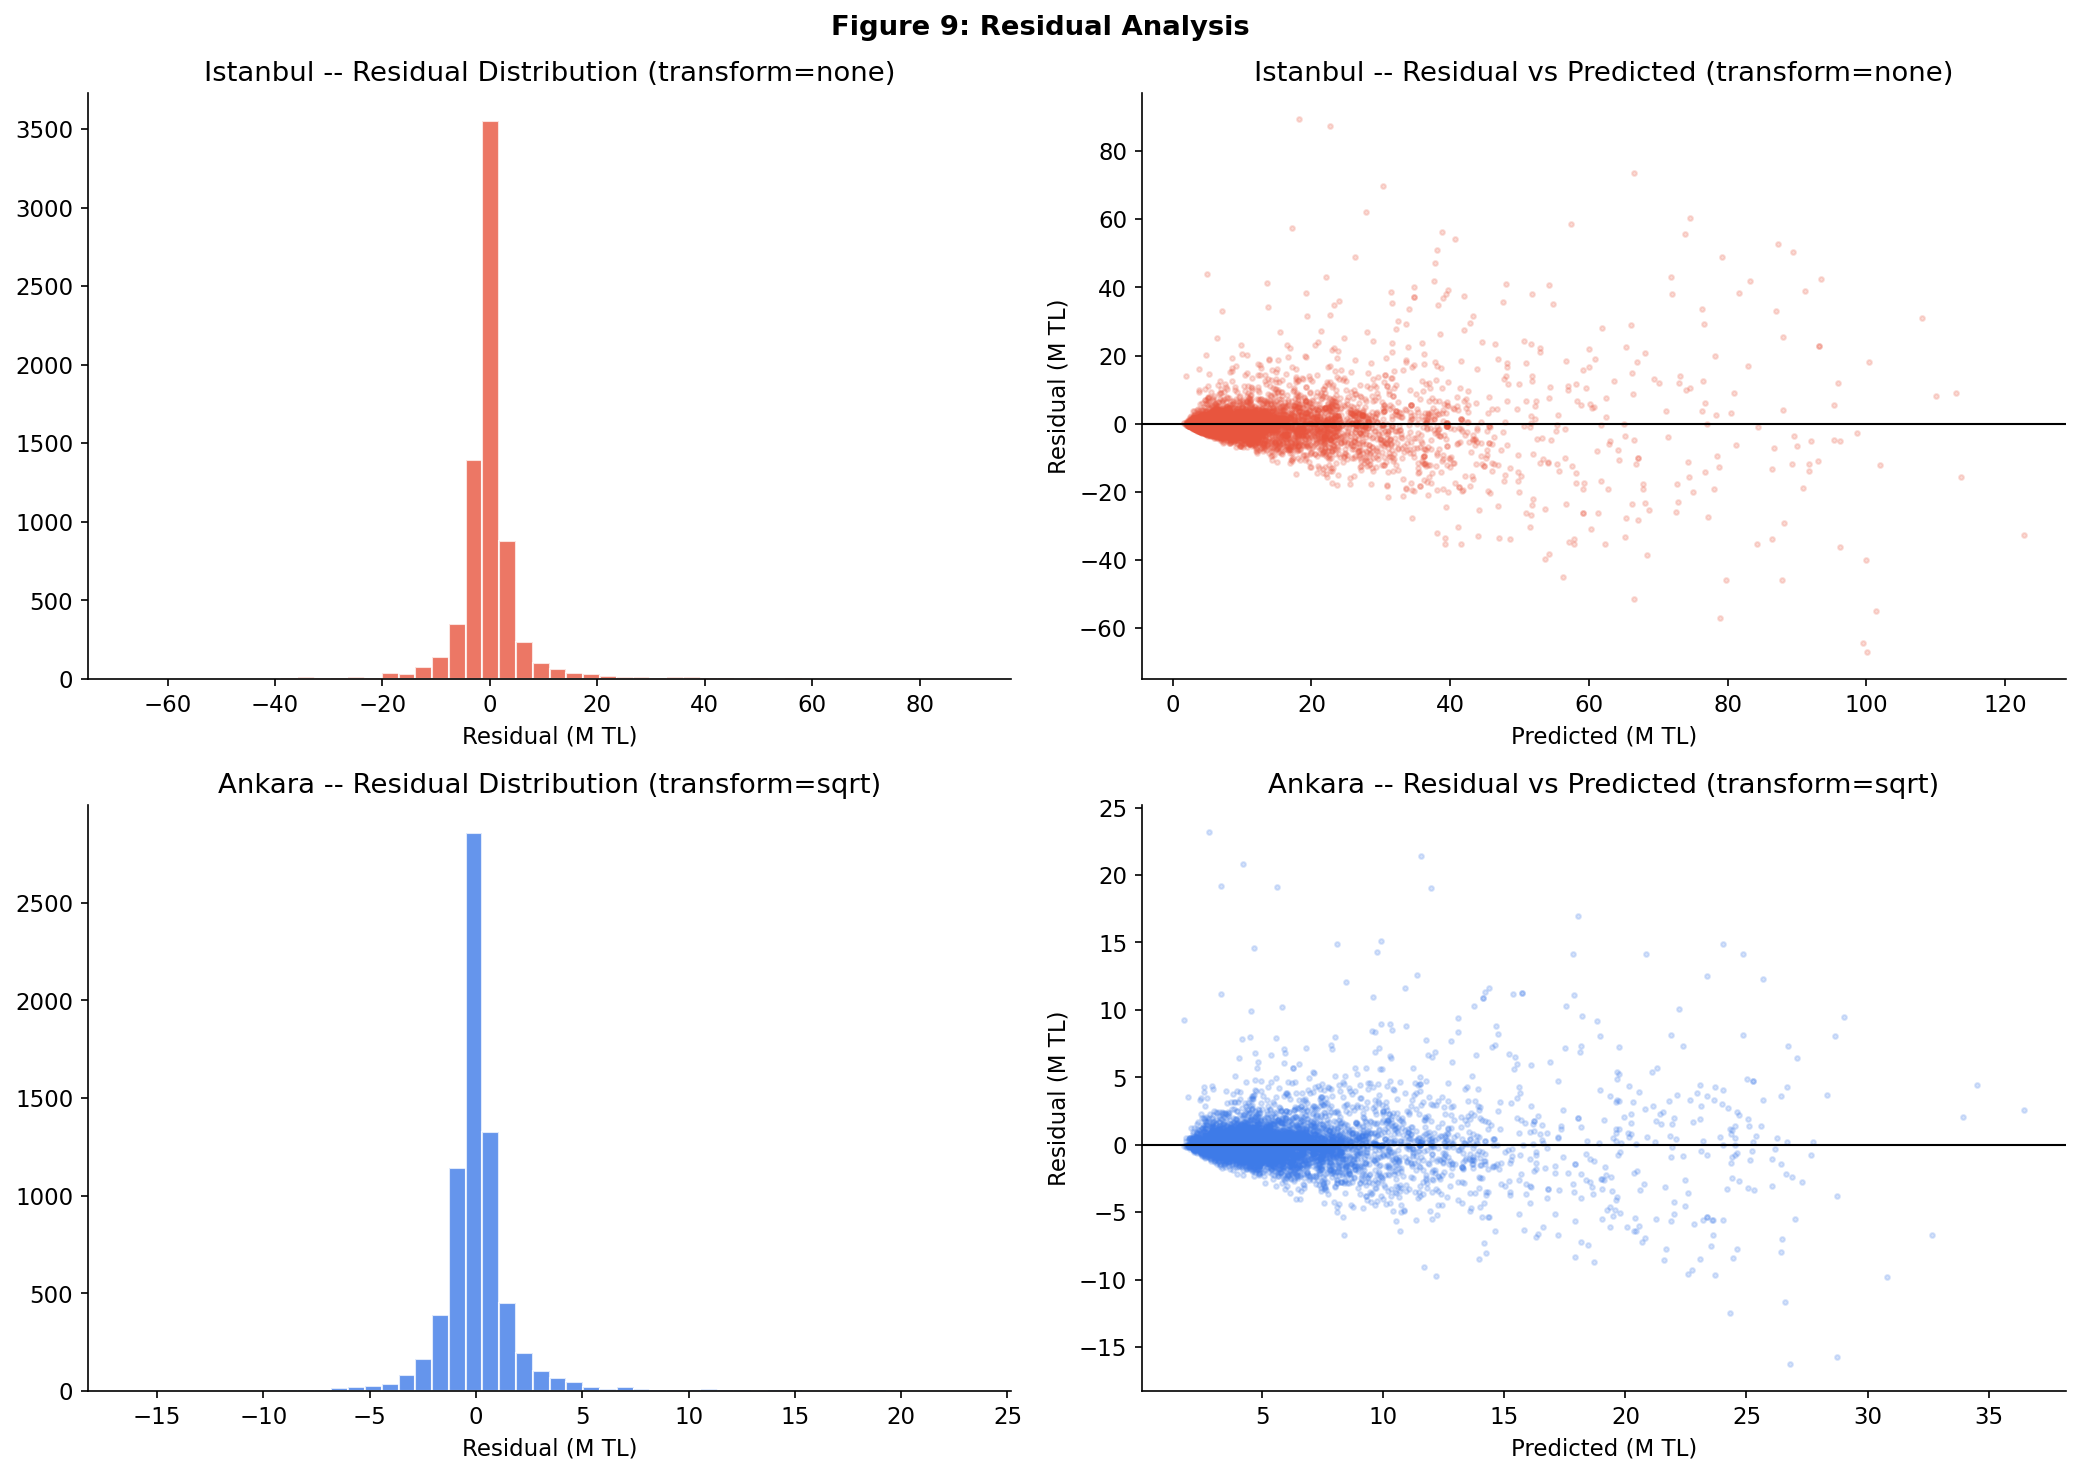

In [30]:
# -- 8.2 Residual Analizi (Normallik & Heteroskedasticity)

from scipy.stats import shapiro

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for row, city in enumerate(['Istanbul', 'Ankara']):
    best_params = studies[city].best_params
    df_city = df[df['city'] == city].copy().reset_index(drop=True)

    tr_idx, val_idx = train_test_split(range(len(df_city)), test_size=0.2, random_state=RANDOM_SEED)
    d_tr  = df_city.iloc[tr_idx].reset_index(drop=True)
    d_val = df_city.iloc[val_idx].reset_index(drop=True)

    X_tr, _, enc_maps = build_features(
        d_tr,
        encoding=best_params.get('encoding', 'frequency'),
        feat_set=best_params.get('feat_set', 'extended'),
        use_stats=best_params.get('use_stats', True), fit=True)
    X_val, _, _ = build_features(
        d_val,
        encoding=best_params.get('encoding', 'frequency'),
        feat_set=best_params.get('feat_set', 'extended'),
        use_stats=best_params.get('use_stats', True),
        fit=False, encoding_maps=enc_maps)

    # Best params'tan target transform al
    tf = best_params.get('target_transform', 'log1p')
    if tf == 'log1p':   y_tr_t = np.log1p(d_tr['Price'])
    elif tf == 'sqrt':  y_tr_t = np.sqrt(d_tr['Price'].clip(0))
    elif tf == 'cbrt':  y_tr_t = np.cbrt(d_tr['Price'])
    else:               y_tr_t = d_tr['Price']

    y_val = d_val['Price'].values

    mt = best_params.get('model_type', 'hgb')
    if mt == 'hgb':
        res_model = HistGradientBoostingRegressor(
            max_iter=best_params.get('n_estimators', 200), random_state=RANDOM_SEED)
    elif mt == 'lgbm' and LGB_AVAILABLE:
        res_model = lgb.LGBMRegressor(
            n_estimators=best_params.get('n_estimators', 200),
            random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)
    else:
        res_model = RandomForestRegressor(
            n_estimators=best_params.get('n_estimators', 200),
            random_state=RANDOM_SEED, n_jobs=-1)

    res_model.fit(X_tr, y_tr_t)
    pred_t = res_model.predict(X_val)

    if tf == 'log1p':   pred = np.expm1(pred_t)
    elif tf == 'sqrt':  pred = pred_t ** 2
    elif tf == 'cbrt':  pred = pred_t ** 3
    else:               pred = pred_t
    pred = np.clip(pred, 0, None)

    residuals = y_val - pred
    color = '#E8553E' if city == 'Istanbul' else '#3E7BE8'

    axes[row, 0].hist(residuals / 1e6, bins=50, color=color, alpha=0.8, edgecolor='white')
    axes[row, 0].set_title(f'{city} -- Residual Distribution (transform={tf})')
    axes[row, 0].set_xlabel('Residual (M TL)')

    axes[row, 1].scatter(pred/1e6, residuals/1e6, alpha=0.2, s=5, color=color)
    axes[row, 1].axhline(y=0, color='black', linewidth=1)
    axes[row, 1].set_title(f'{city} -- Residual vs Predicted (transform={tf})')
    axes[row, 1].set_xlabel('Predicted (M TL)')
    axes[row, 1].set_ylabel('Residual (M TL)')

    sample_res = np.random.choice(residuals, min(500, len(residuals)), replace=False)
    stat, p = shapiro(sample_res)
    r2_val = r2_score(y_val, pred)
    norm = 'Normal' if p > 0.05 else 'Non-normal'
    print(f'{city} -- Shapiro-Wilk: W={stat:.4f}, p={p:.4e} ({norm}) | Val R2={r2_val:.4f} | Transform={tf}')

plt.suptitle('Figure 9: Residual Analysis', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig9_residuals.png', bbox_inches='tight')
plt.show()


In [31]:
# -- 8.3 Sonuc Ozeti -- Makale Discussion Bolumu icin Notlar

print('=' * 60)
print('PAPER DISCUSSION NOTES')
print('=' * 60)
print()

print('RQ1: Optuna Pipeline Performance')
for city in ['Istanbul', 'Ankara']:
    best_r2     = studies[city].best_value
    baseline_r2 = results_baseline.get(city, {}).get('HistGradientBoosting', {}).get('R2_mean', None)
    if baseline_r2:
        gain = best_r2 - baseline_r2
        sign = '+' if gain >= 0 else ''
        print(f'  {city}: Optuna={best_r2:.4f} vs Baseline HGB={baseline_r2:.4f} ({sign}{gain:.4f})')

print()
print('RQ2: Transfer Efficiency')
if 'Ankara_WarmStart' in studies:
    cold_best = studies['Ankara'].best_value
    warm_best = studies['Ankara_WarmStart'].best_value
    print(f'  Cold-Start: {cold_best:.4f}')
    print(f'  Warm-Start: {warm_best:.4f}')
    gain_ws = warm_best - cold_best
    print(f'  Transfer Gain: {gain_ws:+.4f}')
else:
    print('  (Warm-start study not available -- run "5.1 Warm-Start" cell to enable)')

print()
print('RQ3: City-Level Feature Importance')
try:
    if SHAP_AVAILABLE and shap_results:
        for city in ['Istanbul', 'Ankara']:
            top3 = sorted(importance_shap_pct[city].items(), key=lambda x: x[1], reverse=True)[:3]
            print(f'  {city} top-3: {", ".join(f"{k} ({v:.1f}%)" for k,v in top3)}')
except:
    print('  (SHAP results not available)')

print()
print('RQ4: Segment Stratified Model Performance')
for city in ['Istanbul', 'Ankara']:
    print(f'  {city}:')
    for seg in ['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)']:
        g_r2 = seg_results_global.get(city, {}).get(seg, {}).get('R2', float('nan'))
        s_r2 = seg_results_stratified.get(city, {}).get(seg, {}).get('R2', float('nan'))
        imp = 'UP' if s_r2 > g_r2 else 'DOWN'
        print(f'    {seg}: Global={g_r2:.4f}, Stratified={s_r2:.4f} {imp}')

print()
print(f'Statistics: N_BOOTSTRAP={N_BOOTSTRAP}, N_OPTUNA_TRIALS={N_OPTUNA_TRIALS}')
print(f'Total output files: {len(list(RESULTS_DIR.iterdir()))}')
print('Ready: Tables (CSV) + Figures (PNG)')


PAPER DISCUSSION NOTES

RQ1: Optuna Pipeline Performance
  Istanbul: Optuna=0.7946 vs Baseline HGB=0.7420 (+0.0526)
  Ankara: Optuna=0.8232 vs Baseline HGB=0.7869 (+0.0363)

RQ2: Transfer Efficiency
  Cold-Start: 0.8232
  Warm-Start: 0.8264
  Transfer Gain: +0.0031

RQ3: City-Level Feature Importance
  Istanbul top-3: street_enc (38.1%), m2 (30.3%), dist_ymed (9.4%)
  Ankara top-3: str_ym (32.0%), room_m2 (9.7%), str_ymed (9.4%)

RQ4: Segment Stratified Model Performance
  Istanbul:
    Q1 (Low): Global=-3.3011, Stratified=0.4011 UP
    Q2: Global=-5.7184, Stratified=0.2471 UP
    Q3: Global=-1.3089, Stratified=0.4126 UP
    Q4 (High): Global=0.8069, Stratified=0.6260 DOWN
  Ankara:
    Q1 (Low): Global=0.3014, Stratified=0.4345 UP
    Q2: Global=-0.7022, Stratified=0.1777 UP
    Q3: Global=0.1118, Stratified=0.3245 UP
    Q4 (High): Global=0.9293, Stratified=0.7154 DOWN

Statistics: N_BOOTSTRAP=30, N_OPTUNA_TRIALS=300
Total output files: 16
Ready: Tables (CSV) + Figures (PNG)
